# MMIP - Week 10：檢索增強生成（RAG）

延伸 Week 9 的「洗標辨識前處理客服」，建立衣物洗護知識庫並完成作業一～四。

| 作業 | 項目 | Notebook 章節 |
|---|---|---|
| 一 | 自製洗護 QA Dataset（Embedding ≥ 1,000）、多輪對話 RAG + Reference | 1.1 ~ 1.4 |
| 一（進階） | Chunk Size / Overlap / Top-K 穩定度、Prompting Technique、User Interface | 1.5 ~ 1.8 |
| 二 | 多輪對話 VideoRAG（ASR + CLIP + k-means++ Frame Selection + Qwen2-VL）（自錄有說話影片 + 無聲操作影片） | 2.1 ~ 2.6 |
| 三 | 以 RAGAS 指標評估作業一的 RAG 系統 | 3.1 ~ 3.4 |
| 三（進階） | VideoRAG 評估方法設計與實作 | 3.5 |
| 四 | VideoRAG 論文 GraphRAG：建圖、24 題 Benchmark、與 Naive RAG 比較 | 4.1 ~ 4.6 |

**模型：** Embedding `BAAI/bge-m3`、Re-Ranker `BAAI/bge-reranker-v2-m3`、LLM / Judge `Qwen/Qwen2.5-3B-Instruct`、VLM `Qwen/Qwen2-VL-2B-Instruct`、CLIP `openai/clip-vit-base-patch32`、ASR `openai/whisper-small`。

## 0. 環境與共用設定

In [1]:
import os, sys, re, json, time, math, random, gc, hashlib, itertools, warnings, platform
from pathlib import Path
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
DATA, OUT = ROOT / "data", ROOT / "outputs"
CACHE = OUT / "cache"
for p in (OUT, CACHE): p.mkdir(parents=True, exist_ok=True)

QUICK = os.environ.get("W10_QUICK", "0") == "1"        # 少量樣本快速檢查流程
FORCE = os.environ.get("W10_FORCE", "0") == "1"        # 忽略快取全部重算
LAUNCH_UI = os.environ.get("W10_LAUNCH_UI", "1") == "1"  # 是否啟動 Gradio
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

CONFIG = dict(
    embedder="BAAI/bge-m3",
    reranker="BAAI/bge-reranker-v2-m3",
    llm="Qwen/Qwen2.5-3B-Instruct",
    vlm="Qwen/Qwen2-VL-2B-Instruct",
    clip="openai/clip-vit-base-patch32",
    asr="openai/whisper-small",
)
plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "Noto Sans CJK TC", "PingFang TC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_colwidth", 120)

def read_jsonl(p): return [json.loads(l) for l in open(p, encoding="utf-8") if l.strip()]
def write_jsonl(p, rows):
    with open(p, "w", encoding="utf-8") as f:
        for r in rows: f.write(json.dumps(r, ensure_ascii=False) + "\n")
def sfx(name): return name + ("_quick" if QUICK else "")

import transformers
env = dict(python=platform.python_version(), torch=torch.__version__, transformers=transformers.__version__,
           cuda=torch.version.cuda, gpu=torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu",
           quick=QUICK, config=CONFIG)
json.dump(env, open(OUT / "environment.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print(json.dumps(env, ensure_ascii=False, indent=1))

C:\Users\GM100\anaconda3\envs\MMIP-w10\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{
 "python": "3.11.18",
 "torch": "2.14.1+cu126",
 "transformers": "5.22.2",
 "cuda": "12.6",
 "gpu": "NVIDIA GeForce RTX 3060",
 "quick": false,
 "config": {
  "embedder": "BAAI/bge-m3",
  "reranker": "BAAI/bge-reranker-v2-m3",
  "llm": "Qwen/Qwen2.5-3B-Instruct",
  "vlm": "Qwen/Qwen2-VL-2B-Instruct",
  "clip": "openai/clip-vit-base-patch32",
  "asr": "openai/whisper-small"
 }
}


### 0.1 共用模型：Embedding、Re-Ranker、LLM

- **Embedding：** bge-m3 dense（CLS pooling + L2 normalize），中英跨語言皆可，作業一與作業四共用。
- **Re-Ranker：** bge-reranker-v2-m3 Cross-Encoder，輸入 `[CLS] Query [SEP] Chunk [SEP]`，輸出相關機率。
- **LLM：** Qwen2.5-3B-Instruct（bf16），批次 greedy 生成；所有呼叫以 prompt hash 快取在 `outputs/cache/llm_cache.jsonl`，重跑結果一致。

In [2]:
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification, AutoModelForCausalLM

class Embedder:
    def __init__(self, name):
        self.tok = AutoTokenizer.from_pretrained(name)
        self.model = AutoModel.from_pretrained(name, dtype=torch.float16).to(DEVICE).eval()
        self.cache = {}
    @torch.inference_mode()
    def encode(self, texts, bs=32, max_len=512):
        texts = list(texts)
        todo = sorted({t for t in texts if t not in self.cache}, key=len)
        for i in range(0, len(todo), bs):
            b = todo[i:i + bs]
            enc = self.tok(b, padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(DEVICE)
            h = self.model(**enc).last_hidden_state[:, 0]
            v = torch.nn.functional.normalize(h.float(), dim=-1).cpu().numpy()
            for t, e in zip(b, v): self.cache[t] = e
        return np.stack([self.cache[t] for t in texts]) if texts else np.zeros((0, 1024), np.float32)

class Reranker:
    def __init__(self, name):
        self.tok = AutoTokenizer.from_pretrained(name)
        self.model = AutoModelForSequenceClassification.from_pretrained(name, dtype=torch.float16).to(DEVICE).eval()
        self.cache = {}
    @torch.inference_mode()
    def score(self, query, passages, bs=16):
        keys = [(query, p) for p in passages]
        todo = [k for k in dict.fromkeys(keys) if k not in self.cache]
        for i in range(0, len(todo), bs):
            b = todo[i:i + bs]
            enc = self.tok([q for q, _ in b], [p for _, p in b], padding=True, truncation=True, max_length=512, return_tensors="pt").to(DEVICE)
            s = torch.sigmoid(self.model(**enc).logits.view(-1).float()).cpu().numpy()
            for k, v in zip(b, s): self.cache[k] = float(v)
        return np.array([self.cache[k] for k in keys])

class LLM:
    def __init__(self, name, cache_file):
        self.name = name
        self.tok = AutoTokenizer.from_pretrained(name, padding_side="left")
        self.model = AutoModelForCausalLM.from_pretrained(name, dtype=torch.bfloat16, device_map={"": 0}, attn_implementation="sdpa").eval()
        gc_ = self.model.generation_config
        gc_.do_sample, gc_.temperature, gc_.top_p, gc_.top_k = False, None, None, None
        self.cache_file, self.cache, self.stats = cache_file, {}, Counter()
        if cache_file.exists() and not FORCE:
            for l in open(cache_file, encoding="utf-8"):
                r = json.loads(l); self.cache[r["k"]] = r["v"]
    def _key(self, msgs, mnt):
        return hashlib.sha1(json.dumps([self.name, msgs, mnt], ensure_ascii=False).encode()).hexdigest()
    @torch.inference_mode()
    def chat(self, batch, max_new_tokens=256, bs=16, desc=None):
        if len(batch) == 0: return []
        single = isinstance(batch[0], dict)
        batch = [batch] if single else list(batch)
        keys = [self._key(m, max_new_tokens) for m in batch]
        todo = list(dict.fromkeys(i for i, k in enumerate(keys) if k not in self.cache))
        todo = list({keys[i]: i for i in todo}.values())
        prompts = {i: self.tok.apply_chat_template(batch[i], tokenize=False, add_generation_prompt=True) for i in todo}
        order = sorted(todo, key=lambda i: len(prompts[i]))
        it = range(0, len(order), bs)
        if desc and len(order) > bs: it = tqdm(it, desc=desc)
        with open(self.cache_file, "a", encoding="utf-8") as f:
            for j in it:
                ids = order[j:j + bs]
                enc = self.tok([prompts[i] for i in ids], return_tensors="pt", padding=True).to(DEVICE)
                t0 = time.perf_counter()
                out = self.model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=self.tok.pad_token_id)
                self.stats["sec"] += time.perf_counter() - t0
                gen = out[:, enc["input_ids"].shape[1]:]
                self.stats["calls"] += len(ids); self.stats["out_tok"] += int((gen != self.tok.pad_token_id).sum())
                for i, t in zip(ids, self.tok.batch_decode(gen, skip_special_tokens=True)):
                    self.cache[keys[i]] = t.strip()
                    f.write(json.dumps({"k": keys[i], "v": t.strip()}, ensure_ascii=False) + "\n")
        res = [self.cache[k] for k in keys]
        return res[0] if single else res

def parse_json(text, default=None):
    """從 LLM 輸出中取出第一個合法 JSON（容忍 ```json 包裝與前後文字）。"""
    text = re.sub(r"```(?:json)?", "", text)
    dec = json.JSONDecoder()
    for m in re.finditer(r"[\[{]", text):
        try: return dec.raw_decode(text[m.start():])[0]
        except json.JSONDecodeError: continue
    return default

def msgs(system, user): return [{"role": "system", "content": system}, {"role": "user", "content": user}]

_LLM = None
def get_llm():
    """文字 LLM 與 VLM 不同時常駐（12GB 顯存），需要時才載入另一個。"""
    global _LLM
    if _LLM is None:
        if globals().get("_VLM") is not None: globals()["free_vlm"]()
        _LLM = LLM(CONFIG["llm"], CACHE / "llm_cache.jsonl")
    return _LLM
def free_llm():
    global _LLM
    _LLM = None; gc.collect(); torch.cuda.empty_cache()

emb = Embedder(CONFIG["embedder"])
rr = Reranker(CONFIG["reranker"])
get_llm()
print(f"GPU allocated: {torch.cuda.memory_allocated() / 2**30:.2f} GiB")


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]


Loading weights:   1%|▏         | 5/391 [00:01<02:18,  2.78it/s]


Loading weights: 100%|██████████| 391/391 [00:01<00:00, 214.67it/s]


Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]


Loading weights:   2%|▏         | 9/393 [00:00<00:04, 87.22it/s]


Loading weights:  12%|█▏        | 47/393 [00:00<00:01, 255.49it/s]

... (44 outputs left out)


Loading weights:  94%|█████████▎| 406/434 [00:04<00:00, 94.57it/s]


Loading weights:  97%|█████████▋| 419/434 [00:04<00:00, 98.00it/s]


Loading weights: 100%|██████████| 434/434 [00:04<00:00, 89.02it/s]

GPU allocated: 7.86 GiB


---
# 作業一：多輪對話 RAG（衣物洗護 / 洗標知識）

**流程：** Documents → Chunks → Embeddings（數位化）；Query（多輪改寫）→ 相似度檢索 → Re-Ranker → System Prompt + Multi-Turn History + Reference → LLM 回覆。

知識庫 `data/kb/care_kb.txt` 為自行整理的洗護知識：28 份文件、210 條可被引用的事實（每行一條，附 fact id），內容整理自 ISO 3758 / GINETEX / ASTM D5489 / JIS L 0001 等洗標規範與常見洗護知識，並包含 Week 9 洗標辨識系統（YOLO → ResNet）的使用說明。

## 1.1 載入知識庫

In [3]:
def load_kb(path):
    docs, cur = [], None
    for line in open(path, encoding="utf-8"):
        line = line.rstrip("\n")
        if line.startswith("# DOC"):
            did, title, cat = [s.strip() for s in line[5:].split("|")]
            cur = dict(doc_id=did, title=title, category=cat, facts=[]); docs.append(cur)
        elif line.startswith("#") or not line.strip():
            continue
        else:
            fid, text = line.split(" ", 1)
            cur["facts"].append(dict(fid=fid, text=text.strip()))
    for d in docs:   # 文件全文 + 每條事實在全文中的字元區間（之後用來判斷 chunk 是否涵蓋正解）
        text, spans = f"【{d['title']}】", {}
        for f in d["facts"]:
            spans[f["fid"]] = (len(text), len(text) + len(f["text"])); text += f["text"]
        d["text"], d["spans"] = text, spans
    return docs

KB = load_kb(DATA / "kb" / "care_kb.txt")
FACTS = {f["fid"]: dict(**f, doc_id=d["doc_id"], title=d["title"], category=d["category"]) for d in KB for f in d["facts"]}
DOC_BY_ID = {d["doc_id"]: d for d in KB}
kb_stats = pd.DataFrame([dict(類別=d["category"], 文件=d["title"], 事實數=len(d["facts"]), 字數=len(d["text"])) for d in KB])
display(kb_stats.groupby("類別").agg(文件數=("文件", "count"), 事實數=("事實數", "sum"), 字數=("字數", "sum")).sort_values("事實數", ascending=False))
print(f"共 {len(KB)} 份文件、{len(FACTS)} 條事實、{kb_stats.字數.sum():,} 字")

,文件數,事實數,字數
類別,,,
材質保養,13,78,2936
洗標符號,6,59,2268
去漬,3,28,969
洗滌技巧,2,16,566
洗標辨識系統,2,12,485
晾曬收納,1,9,299
疑難排解,1,8,360


共 28 份文件、210 條事實、7,883 字


## 1.2 自製 QA Dataset（doc2query，將 Q 轉成 Embedding）

把文本轉成 QA 形式並將 **Q** 轉成 Embedding，且在問題中加入 **5W1H** 元素，使 Q 更貼近使用情境。

對每條事實請 LLM 產生 5 個不同問法（什麼 / 為什麼 / 怎麼做 / 什麼時候 / 哪些衣物 / 口語提問），答案即為該事實。資料集存於 `data/qa_dataset.jsonl`。

In [4]:
QA_PATH = DATA / "qa_dataset.jsonl"
QA_SYS = "你是衣物洗護客服的資料標註員，負責替知識庫產生使用者會問的問題。"
def qa_prompt(f):
    return msgs(QA_SYS, f"""根據下面這段知識，產生 5 個「使用者可能會問、而且能由這段知識回答」的繁體中文問題。
要求：
1. 問法要多樣，涵蓋 5W1H（什麼、為什麼、怎麼做、什麼時候、哪些衣物）與口語化提問。
2. 問題要像真實使用者說的話，不要照抄原句，也不要出現「這段知識」等字眼。
3. 只輸出 JSON 字串陣列，例如 ["問題一", "問題二", ...]。

主題：{f['title']}
知識：{f['text']}""")

if QA_PATH.exists() and not FORCE:
    QA = read_jsonl(QA_PATH)
else:
    fl = list(FACTS.values())
    outs = get_llm().chat([qa_prompt(f) for f in fl], max_new_tokens=320, desc="doc2query")
    QA = []
    for f, o in zip(fl, outs):
        qs = parse_json(o, []) or []
        qs = [q.strip() for q in qs if isinstance(q, str) and 4 <= len(q.strip()) <= 80]
        for j, q in enumerate(dict.fromkeys(qs)):
            QA.append(dict(qa_id=f"{f['fid']}-q{j+1}", fid=f["fid"], doc_id=f["doc_id"], question=q, answer=f["text"]))
    write_jsonl(QA_PATH, QA)
qa_df = pd.DataFrame(QA)
print(f"QA pairs：{len(QA)}（平均每條事實 {len(QA) / len(FACTS):.2f} 題）")
display(qa_df.sample(8, random_state=1)[["fid", "question", "answer"]])

QA pairs：1050（平均每條事實 5.00 題）


,fid,question,answer
49,OV10,有哪些基本的洗標符號我可以從衣服上找到？,台灣的紡織品保養符號標示可參考 CNS 15291，內容與 ISO 3758 相對應。
779,ST03,除了衣領和袖口，還有其他部位需要特別注意嗎？,衣領與袖口的皮脂汙垢，可在洗前塗抹洗碗精或衣領專用清潔劑並輕刷。
358,WO06,什麼時候需要特別注意清洗羊毛和喀什米爾？,喀什米爾（山羊絨）比一般羊毛更細緻，建議手洗或乾洗，起毛球時可用毛球梳輕輕梳除。
991,LP01,為什麼洗標要攤平拍攝？,拍攝洗標時應將洗標攤平，讓所有符號完整入鏡，不要只拍局部。
639,FB03,高溫烘乾對含有多少比例彈性纖維的衣服影響最大？,成分中即使只含 5% 左右的彈性纖維，即使主成分是棉，也應避免高溫烘乾。
1027,LS02,洗滌建議是如何整理的？,辨識結果會依 ISO 3758 的五大類（水洗、漂白、乾燥、熨燙、專業護理）整理成洗滌建議。
60,WA01,什麼符號代表家庭水洗？,洗衣盆（水盆）符號代表家庭水洗，盆中的數字表示最高水溫（攝氏）。
108,WA10,手洗時要注意什麼？,手洗時應輕壓、輕搓，避免用力扭轉或搓揉，以免衣物變形或起毛球。


## 1.3 Chunking、Index 與檢索器

- **Chunk：** 依字元長度切塊（`chunk_size`、`overlap`），每個 chunk 加註文件標題與字元座標（講義：為每個 Chunk 註記座標資訊）。
- **正解判定：** 若某 chunk 涵蓋某事實 ≥ 60% 的字元，即視為涵蓋該事實；Benchmark 的每題都標註了正解 fact id。
- **兩種 Index：** Chunk Index（chunk 向量）與 QA Index（問題向量，命中後回傳對應事實）。Hybrid 以 RRF 融合兩者。
- **指標：** 講義「繁中檢索能力評測」的計分法（正確段落第 1 名得 1 分、第 2 名 1/2、…、前 5 筆都沒有得 0）＝ **MRR@5**；另計 Recall@K（正解事實被涵蓋比例）與 Precision@K。

In [5]:
def chunk_corpus(size, overlap):
    chunks = []
    for d in KB:
        text, step = d["text"], max(1, size - overlap)
        starts = list(range(0, max(1, len(text) - overlap), step))
        for s in starts:
            e = min(len(text), s + size)
            cov = {fid for fid, (a, b) in d["spans"].items() if min(e, b) - max(s, a) >= 0.6 * (b - a)}
            chunks.append(dict(pid=f"{d['doc_id']}#{s}", kind="chunk", doc_id=d["doc_id"], title=d["title"],
                               start=s, end=e, text=text[s:e], facts=cov))
            if e >= len(text): break
    return chunks

def passage_text(p):  # 給 embedding / reranker / LLM 看的文字（含標題 metadata）
    return p["text"] if p["text"].startswith("【") else f"【{p['title']}】{p['text']}"

FACT_PASSAGES = {fid: dict(pid=f"F:{fid}", kind="fact", doc_id=f["doc_id"], title=f["title"], start=-1, end=-1,
                           text=f["text"], facts={fid}) for fid, f in FACTS.items()}

class Retriever:
    """Chunk Index + QA Index；search() 回傳以 RRF 融合後的候選段落。"""
    def __init__(self, chunks, use_qa=True):
        self.chunks = chunks
        self.CE = emb.encode([passage_text(c) for c in chunks])
        self.use_qa = use_qa
        self.QE = emb.encode([q["question"] for q in QA]) if use_qa else None
    def _chunk_rank(self, qv, k):
        s = self.CE @ qv; idx = np.argsort(-s)[:k]
        return [(self.chunks[i], float(s[i])) for i in idx]
    def _qa_rank(self, qv, k):
        s = self.QE @ qv; seen, out = set(), []
        for i in np.argsort(-s):
            fid = QA[i]["fid"]
            if fid in seen: continue
            seen.add(fid); out.append((FACT_PASSAGES[fid], float(s[i])))
            if len(out) >= k: break
        return out
    def search(self, queries, k=20, mode="hybrid", rrf_k=60):
        queries = [queries] if isinstance(queries, str) else queries
        qvs = emb.encode(queries)
        fused, best = defaultdict(float), {}
        for qv in qvs:
            lists = []
            if mode in ("chunk", "hybrid"): lists.append(self._chunk_rank(qv, k))
            if mode in ("qa", "hybrid") and self.use_qa: lists.append(self._qa_rank(qv, k))
            for lst in lists:
                for r, (p, s) in enumerate(lst):
                    fused[p["pid"]] += 1 / (rrf_k + r + 1); best[p["pid"]] = p
        return [best[pid] for pid, _ in sorted(fused.items(), key=lambda x: -x[1])][:k]

def dedup_passages(ps):
    """移除被前面 chunk 完全涵蓋的事實段落，避免同一資訊重複放入 context。"""
    out, covered = [], set()
    for p in ps:
        if p["kind"] == "fact" and p["facts"] <= covered: continue
        out.append(p); covered |= p["facts"]
    return out

def retrieval_metrics(ranked, gold, ks=(1, 3, 5, 8)):
    gold = set(gold); m = {}
    first = next((r + 1 for r, p in enumerate(ranked[:5]) if p["facts"] & gold), None)
    m["MRR@5"] = 1 / first if first else 0.0
    for k in ks:
        top = ranked[:k]
        m[f"Recall@{k}"] = len(set().union(*[p["facts"] for p in top]) & gold) / len(gold) if top else 0.0
        m[f"P@{k}"] = np.mean([bool(p["facts"] & gold) for p in top]) if top else 0.0
        m[f"Chars@{k}"] = sum(len(p["text"]) for p in top)
    return m

ST = read_jsonl(DATA / "benchmark" / "single_turn.jsonl")
MT = read_jsonl(DATA / "benchmark" / "multi_turn.jsonl")
ST_IN = [x for x in ST if x["gold"]]
ST_OOS = [x for x in ST if not x["gold"]]
print(f"Benchmark：單輪 {len(ST_IN)} 題 + 範圍外 {len(ST_OOS)} 題；多輪 {len(MT)} 段對話、{sum(len(d['turns']) for d in MT)} 輪")

Benchmark：單輪 70 題 + 範圍外 4 題；多輪 16 段對話、48 輪


### Embedding 數量統計（作業一基礎：自製 QA Dataset，Embedding 數量）

以 1.5 選出的設定為準（此處先以 chunk_size=150、overlap=30 統計，最終設定見 1.5）。

In [6]:
_tmp_chunks = chunk_corpus(150, 30)
n_emb = dict(QA_問題向量=len(QA), Chunk向量=len(_tmp_chunks), 事實段落=len(FACT_PASSAGES))
display(pd.DataFrame([n_emb | {"合計": sum(n_emb.values())}]))

,QA_問題向量,Chunk向量,事實段落,合計
0,1050,73,210,1333


## 1.4 多輪對話 RAG 系統

`CareRAG.answer(history, user)` 的步驟：

1. **Query Rewriting：** 依對話紀錄（最近 4 句使用者發言）補齊代名詞與省略（「那它可以烘嗎？」→「羊毛大衣可以用烘衣機烘乾嗎？」）。
2. **檢索：** Hybrid（Chunk + QA Index）取 20 個候選 → **Re-Ranker** 重排 → 去重後取 Top-K。
3. **檢索評估閘門（Corrective-RAG / Self-RAG 概念）：** 最高 re-rank 分數低於門檻 τ 時，視為知識庫無相關資料，直接婉拒，不讓 LLM 自由發揮。τ 以 QA Dataset 的合成問題校準（取其 top-1 分數的第 2 百分位），不使用測試題。
4. **生成：** System Prompt（只依資料、標註引用、資料不足就說不知道）+ 多輪歷史 + 編號參考資料 → 回覆並附 Reference。

最佳 chunk / Top-K / Prompting 設定由 1.5、1.6 實驗決定，這裡先建立系統並示範。

In [7]:
REFUSAL = "抱歉，知識庫中沒有相關資訊。我只能回答衣物洗護與洗標相關的問題。"
REFUSAL_PAT = re.compile(r"(沒有相關資訊|無法回答|只能回答.*洗|超出.*範圍|不在.*範圍|無相關資料|知識庫中沒有)")
def is_refusal(ans):
    """回答很短且含婉拒語，或一開頭就婉拒，才算婉拒（避免「先回答、最後補一句沒有其他資訊」被誤判）。"""
    m = REFUSAL_PAT.search(ans)
    return bool(m) and (len(ans) < 60 or m.start() < 20)

REWRITE_SYS = "你是查詢改寫器，負責把多輪對話中的最新問題改寫成可以單獨拿去檢索的完整問題。"
def rewrite_prompt(history_users, user, history_bot=None):
    lines = []
    for i, u in enumerate(history_users):
        lines.append(f"使用者：{u}")
        if history_bot and i < len(history_bot) and history_bot[i]:
            lines.append(f"助理：{history_bot[i][:120]}")
    hist = "\n".join(lines) if lines else "（無）"
    return msgs(REWRITE_SYS, f"""請根據對話紀錄，把「最新問題」改寫成一個獨立、完整的繁體中文問題：
- 補齊代名詞與省略的主詞（例如「它」「那」「這件」指的是哪件衣物、哪個符號或哪種汙漬）。
- 保留原本的問題意圖，不要回答問題，不要加入對話中沒有的資訊。
- 若最新問題本身已經完整，就原樣輸出。
只輸出改寫後的問題，不要有其他文字。

對話紀錄：
{hist}

最新問題：{user}
改寫後的問題：""")

def clean_rewrite(text, fallback):
    t = text.strip().split("\n")[0].strip().strip("「」\"'")
    t = re.sub(r"^(改寫後的問題|問題)[:：]\s*", "", t)
    return t if 2 <= len(t) <= 120 else fallback

# ---------- 其他 Query 轉換技術（1.6 比較） ----------
def multiquery_prompt(q):
    return msgs("你是檢索查詢擴寫器。", f"請為下面的問題寫出 3 個意思相同、但用詞與問法不同的繁體中文檢索查詢。只輸出 JSON 字串陣列。\n問題：{q}")
def stepback_prompt(q):
    return msgs("你是擅長抽象化問題的助理（Step-Back Prompting）。",
                f"請把下面的具體問題退一步，改寫成一個更一般、更基礎的背景問題（例如詢問原理、符號類別或材質特性），幫助查找背景知識。只輸出一個問題。\n具體問題：{q}\n退一步的問題：")
def hyde_prompt(q):
    return msgs("你是衣物洗護專家。", f"請用 2~3 句繁體中文直接回答下面的問題（像知識庫條目的寫法，不用加註解）。\n問題：{q}\n回答：")

# ---------- 生成 Prompt（1.6 比較） ----------
GEN_PROMPTS = {
    "G1-基本": dict(system="你是衣物洗護助理。", rules=""),
    "G2-嚴格依據+引用": dict(system="你是「洗標小幫手」，專門回答衣物洗護與洗標符號問題的客服助理。", rules="""回答規則：
1. 只能根據【參考資料】回答，不可使用參考資料以外的知識或自行推測。
2. 每個關鍵句子後面用 [編號] 標註引用的參考資料，例如「羊毛不可烘乾 [2]」。
3. 參考資料不足以回答時，回答「知識庫中沒有相關資訊」，不要編造。
4. 用繁體中文，先直接回答，再補充必要的注意事項，3~5 句以內。"""),
}
GEN_PROMPTS["G3-嚴格+單例示範"] = dict(system=GEN_PROMPTS["G2-嚴格依據+引用"]["system"], rules=GEN_PROMPTS["G2-嚴格依據+引用"]["rules"] + """

範例：
【參考資料】
[1] 【水洗符號】水盆內寫 30 表示最高水溫 30°C，適合深色、易褪色或較嬌貴的衣物。
[2] 【棉與麻】深色棉 T 恤建議翻面、以 30°C 以下的冷水洗滌並陰乾，可減少褪色。
問題：洗衣盆裡寫 30 是什麼意思？
回答：代表水洗時水溫最高 30°C [1]。這類標示常見於深色或易褪色的衣物，洗的時候可以翻面並陰乾，減少褪色 [2]。""")
GEN_PROMPTS["G4-先反思再回答"] = dict(system=GEN_PROMPTS["G2-嚴格依據+引用"]["system"], rules=GEN_PROMPTS["G2-嚴格依據+引用"]["rules"] + """
5. 作答前先自我檢查（Self-RAG 反思）：第一行寫「相關資料：」列出真正有用的編號（都沒用就寫「無」），第二行起寫「回答：」再作答。""")

def gen_prompt(style, history, user, query, passages):
    cfg = GEN_PROMPTS[style]
    ref = "\n".join(f"[{i+1}] {passage_text(p)}" for i, p in enumerate(passages))
    hist = "\n".join(f"使用者：{h['user']}\n助理：{h['bot'][:200]}" for h in history[-3:]) if history else "（無）"
    user_msg = f"""{cfg['rules']}

【對話紀錄】
{hist}

【參考資料】
{ref}

問題：{user}{'（完整問題：' + query + '）' if query != user else ''}
回答："""
    return msgs(cfg["system"], user_msg.strip())

def postprocess_answer(style, text):
    if style == "G4-先反思再回答":
        head = re.search(r"相關資料[:：]([^\n]*)", text)
        refs = sorted({int(x) for x in re.findall(r"\d+", head.group(1))}) if head else []
        m = re.search(r"回答[:：]\s*(.*)", text, flags=re.S)
        text = m.group(1).strip() if m else re.sub(r"^相關資料[:：].*\n?", "", text).strip()
        if refs and not re.search(r"\[\d+\]", text):   # 回答本身沒標引用時，附上模型自評的相關資料編號
            text += "（依據 " + "".join(f"[{r}]" for r in refs) + "）"
    return text

def cited_ids(answer, n):
    return sorted({int(x) for x in re.findall(r"\[(\d+)\]", answer) if 1 <= int(x) <= n})

class CareRAG:
    def __init__(self, retriever, k=5, technique="rewrite", gen_style="G2-嚴格依據+引用", rerank=True, gate=True,
                 tau=0.0, n_cand=20, mode="hybrid"):
        self.R, self.k, self.technique, self.gen_style = retriever, k, technique, gen_style
        self.rerank, self.gate, self.tau, self.n_cand, self.mode = rerank, gate, tau, n_cand, mode

    # ---- Query 轉換（批次版：一次處理多個對話的同一輪） ----
    def transform_batch(self, histories, users):
        """回傳 [(用於 rerank / 顯示的主查詢, 用於向量檢索的查詢列表), ...]。"""
        t, L = self.technique, get_llm()
        if t == "raw": return [(u, [u]) for u in users]
        if t == "concat":
            return [((q := " ".join([h["user"] for h in hs][-2:] + [u])), [q]) for hs, u in zip(histories, users)]
        need = [i for i, hs in enumerate(histories) if hs]
        qs = list(users)
        if need:
            # 只給使用者發言：實測把助理的長回答放進來，3B 模型反而常漏掉「它」指的對象
            outs = L.chat([rewrite_prompt([h["user"] for h in histories[i]][-4:], users[i]) for i in need], max_new_tokens=64)
            for i, o in zip(need, outs): qs[i] = clean_rewrite(o, users[i])
        if t == "rewrite": return [(q, [q]) for q in qs]
        if t == "multiquery":
            outs = L.chat([multiquery_prompt(q) for q in qs], max_new_tokens=160)
            return [(q, [q] + [x for x in (parse_json(o, []) or []) if isinstance(x, str)][:3]) for q, o in zip(qs, outs)]
        if t == "stepback":
            outs = L.chat([stepback_prompt(q) for q in qs], max_new_tokens=64)
            return [(q, [q, clean_rewrite(o, q)]) for q, o in zip(qs, outs)]
        if t == "hyde":
            outs = L.chat([hyde_prompt(q) for q in qs], max_new_tokens=120)
            return [(q, [q, o]) for q, o in zip(qs, outs)]
        raise ValueError(t)
    def transform(self, history, user): return self.transform_batch([history], [user])[0]

    def retrieve(self, query, queries):
        cands = self.R.search(queries, k=self.n_cand, mode=self.mode)
        if self.rerank and cands:
            s = rr.score(query, [passage_text(p) for p in cands])
            order = np.argsort(-s)
            cands, scores = [cands[i] for i in order], s[order]
        else:
            scores = np.ones(len(cands))
        return cands, scores

    def answer_batch(self, histories, users, k=None):
        k = k or self.k; t0 = time.perf_counter()
        trs = self.transform_batch(histories, users)
        outs = []
        for (query, queries) in trs:
            cands, scores = self.retrieve(query, queries)
            top = dedup_passages(cands)[:k]
            max_s = float(scores[0]) if len(scores) else 0.0
            outs.append(dict(query=query, queries=queries, retrieved=top, max_score=max_s,
                             gated=bool(self.gate and self.rerank and max_s < self.tau)))
        gi = [i for i, o in enumerate(outs) if not o["gated"]]
        raws = get_llm().chat([gen_prompt(self.gen_style, histories[i], users[i], outs[i]["query"], outs[i]["retrieved"]) for i in gi], max_new_tokens=320) if gi else []
        raw_of = dict(zip(gi, raws))
        dt = (time.perf_counter() - t0) / max(1, len(users))
        res = []
        for i, (o, u) in enumerate(zip(outs, users)):
            ans = postprocess_answer(self.gen_style, raw_of[i]) if i in raw_of else REFUSAL
            res.append(dict(user=u, query=o["query"], queries=o["queries"], answer=ans, passages=o["retrieved"] if i in raw_of else [],
                            retrieved=o["retrieved"], max_score=o["max_score"], refused=is_refusal(ans), latency=dt))
        return res
    def answer(self, history, user, k=None): return self.answer_batch([history], [user], k)[0]

def format_refs(out):
    if not out["passages"]: return "（未引用任何資料）"
    cid = set(cited_ids(out["answer"], len(out["passages"])))
    rows = []
    for i, p in enumerate(out["passages"]):
        mark = "✅" if (i + 1) in cid else "▫️"
        fids = ",".join(sorted(p["facts"])) or "-"
        rows.append(f"{mark} [{i+1}] 《{p['title']}》 `{p['pid']}` 事實:{fids}｜{p['text'][:60]}…")
    return "\n".join(rows)

In [8]:
# 先以預設設定建立 Retriever，校準閘門門檻 τ（用 QA Dataset 合成問題，不碰測試題）
retr_default = Retriever(chunk_corpus(150, 30))
rng = np.random.default_rng(SEED)
calib = [QA[i] for i in rng.choice(len(QA), 200, replace=False)]
calib_scores = []
for q in calib:
    c = retr_default.search(q["question"], k=10)
    calib_scores.append(rr.score(q["question"], [passage_text(p) for p in c]).max())
TAU = float(np.percentile(calib_scores, 2))
print(f"閘門門檻 τ = {TAU:.4f}（合成問題 top-1 re-rank 分數中位數 {np.median(calib_scores):.3f}）")

閘門門檻 τ = 0.0262（合成問題 top-1 re-rank 分數中位數 0.892）


In [9]:
def run_dialog(bot, turns, use_gold_history=False):
    history, outs = [], []
    for t in turns:
        o = bot.answer(history, t["q"])
        o["gold"] = t.get("gold", [])
        outs.append(o)
        history.append(dict(user=t["q"], bot=o["answer"]))
    return outs

demo_bot = CareRAG(retr_default, k=5, technique="rewrite", tau=TAU)
demo_md = []
for d in [MT[0], MT[1], MT[4]]:
    demo_md.append(f"### 對話 {d['did']}")
    for o in run_dialog(demo_bot, d["turns"]):
        demo_md.append(f"**👤 使用者：** {o['user']}  \n**🔎 改寫查詢：** {o['query']}  \n**🤖 回覆：** {o['answer']}  \n**📚 Reference：**\n```\n{format_refs(o)}\n```")
(OUT / "hw1_demo_dialogs.md").write_text("\n\n".join(demo_md), encoding="utf-8")
display(Markdown("\n\n".join(demo_md)))

### 對話 M01

**👤 使用者：** 我有一件羊毛大衣想自己洗  
**🔎 改寫查詢：** 我有一件羊毛大衣想自己洗  
**🤖 回覆：** 羊毛大衣應使用 30°C 以下的冷水，搭配羊毛專用或中性洗劑，以手洗或洗衣機的羊毛洗程處理。洗後應用毛巾捲壓吸水，再平放陰乾，不可吊掛，以免被拉長變形。羊毛大衣不可滾筒烘乾，熱與翻滾會造成縮絨。穿後掛在通風處讓纖維回復，可延長衣物壽命。請注意，羊毛與蠶絲不可使用含酵素（蛋白酶）的洗衣精。  
**📚 Reference：**
```
▫️ [1] 《羊毛與喀什米爾》 `F:WO02` 事實:WO02｜羊毛衣物應使用 30°C 以下的冷水，搭配羊毛專用或中性洗劑，以手洗或洗衣機的羊毛洗程處理。…
▫️ [2] 《合成纖維（聚酯、尼龍、壓克力）》 `fiber_synth#120` 事實:SY04,SY05,SY06｜，建議冷水洗滌、低溫熨燙或不熨燙。壓克力纖維（Acrylic）常用於仿羊毛衣物，怕熱，烘乾或高溫熨燙容易失去彈性而變形。…
▫️ [3] 《羊毛與喀什米爾》 `fiber_wool#120` 事實:WO04,WO05,WO06,WO07｜洗衣精，因為蛋白酶會分解蛋白質纖維。羊毛衣洗後應用毛巾捲壓吸水，再平放陰乾，不可吊掛，以免被拉長變形。羊毛衣物不可滾筒烘…
▫️ [4] 《羊毛與喀什米爾》 `fiber_wool#0` 事實:WO01,WO02,WO03｜【羊毛與喀什米爾】羊毛屬於蛋白質纖維，表面有鱗片，遇到熱水加上搓揉會產生「縮絨（氈化）」而嚴重縮水，且無法復原。羊毛衣物…
▫️ [5] 《羊毛與喀什米爾》 `fiber_wool#240` 事實:WO07,WO08,WO09｜後都洗，穿後掛在通風處讓纖維回復，可延長衣物壽命。羊毛衣物收納前應先洗淨，並放置防蟲劑，避免衣蛾蛀蝕。標示「可機洗羊毛（…
```

**👤 使用者：** 那它可以用洗衣機烘乾嗎？  
**🔎 改寫查詢：** 那件羊毛大衣可以用洗衣機烘乾嗎？  
**🤖 回覆：** 不可以，羊毛大衣不可滾筒烘乾，熱與翻滾會造成縮絨。[1]  
**📚 Reference：**
```
✅ [1] 《羊毛與喀什米爾》 `F:WO05` 事實:WO05｜羊毛衣物不可滾筒烘乾，熱與翻滾會造成縮絨。…
▫️ [2] 《羊毛與喀什米爾》 `fiber_wool#120` 事實:WO04,WO05,WO06,WO07｜洗衣精，因為蛋白酶會分解蛋白質纖維。羊毛衣洗後應用毛巾捲壓吸水，再平放陰乾，不可吊掛，以免被拉長變形。羊毛衣物不可滾筒烘…
▫️ [3] 《羊毛與喀什米爾》 `fiber_wool#240` 事實:WO07,WO08,WO09｜後都洗，穿後掛在通風處讓纖維回復，可延長衣物壽命。羊毛衣物收納前應先洗淨，並放置防蟲劑，避免衣蛾蛀蝕。標示「可機洗羊毛（…
▫️ [4] 《合成纖維（聚酯、尼龍、壓克力）》 `fiber_synth#120` 事實:SY04,SY05,SY06｜，建議冷水洗滌、低溫熨燙或不熨燙。壓克力纖維（Acrylic）常用於仿羊毛衣物，怕熱，烘乾或高溫熨燙容易失去彈性而變形。…
▫️ [5] 《羊毛與喀什米爾》 `F:WO02` 事實:WO02｜羊毛衣物應使用 30°C 以下的冷水，搭配羊毛專用或中性洗劑，以手洗或洗衣機的羊毛洗程處理。…
```

**👤 使用者：** 洗完要怎麼晾？  
**🔎 改寫查詢：** 洗完之後該如何晾乾這件羊毛大衣？  
**🤖 回覆：** 洗完之後應將羊毛大衣平放陰乾，不可吊掛，以免被拉長變形。[1]  
**📚 Reference：**
```
✅ [1] 《羊毛與喀什米爾》 `F:WO04` 事實:WO04｜羊毛衣洗後應用毛巾捲壓吸水，再平放陰乾，不可吊掛，以免被拉長變形。…
▫️ [2] 《羊毛與喀什米爾》 `fiber_wool#120` 事實:WO04,WO05,WO06,WO07｜洗衣精，因為蛋白酶會分解蛋白質纖維。羊毛衣洗後應用毛巾捲壓吸水，再平放陰乾，不可吊掛，以免被拉長變形。羊毛衣物不可滾筒烘…
▫️ [3] 《羊毛與喀什米爾》 `fiber_wool#0` 事實:WO01,WO02,WO03｜【羊毛與喀什米爾】羊毛屬於蛋白質纖維，表面有鱗片，遇到熱水加上搓揉會產生「縮絨（氈化）」而嚴重縮水，且無法復原。羊毛衣物…
▫️ [4] 《晾曬與收納》 `F:DS03` 事實:DS03｜襯衫洗後可趁濕拉平領子與袖口，用衣架吊掛晾乾，可減少熨燙的需求。…
▫️ [5] 《合成纖維（聚酯、尼龍、壓克力）》 `fiber_synth#120` 事實:SY04,SY05,SY06｜，建議冷水洗滌、低溫熨燙或不熨燙。壓克力纖維（Acrylic）常用於仿羊毛衣物，怕熱，烘乾或高溫熨燙容易失去彈性而變形。…
```

### 對話 M02

**👤 使用者：** 洗標上有一個三角形裡面兩條斜線  
**🔎 改寫查詢：** 洗標上有一個三角形裡面兩條斜線  
**🤖 回覆：** 洗標上有一個三角形裡面兩條斜線，表示只能使用氧系（非氯）漂白劑，不可使用含氯漂白水。[1]  
**📚 Reference：**
```
✅ [1] 《漂白符號（三角形）》 `F:BL03` 事實:BL03｜三角形內有兩條斜線，表示只能使用氧系（非氯）漂白劑，不可使用含氯漂白水。…
▫️ [2] 《漂白符號（三角形）》 `sym_bleach#0` 事實:BL01,BL02,BL03,BL04,BL05｜【漂白符號（三角形）】三角形符號代表漂白處理，位於洗標符號的第二個位置。空白三角形表示可使用任何漂白劑，包括含氯漂白水與…
▫️ [3] 《水洗符號（洗衣盆）》 `F:WA08` 事實:WA08｜水盆下方有兩條橫線，表示需使用非常溫和的洗程，例如洗衣機的羊毛或絲質專用洗程。…
▫️ [4] 《洗標符號總覽》 `sym_overview#120` 事實:OV04,OV05,OV06｜為：水洗盆、漂白三角形、乾燥方框、熨斗、專業護理圓圈。任何保養符號上加一個「X」叉號，表示禁止該項處理，例如水盆打叉代表…
▫️ [5] 《漂白符號（三角形）》 `sym_bleach#120` 事實:BL05,BL06,BL07,BL08｜式洗標可能在三角形內寫「CL」，代表可使用含氯漂白劑；現行 ISO 已改為空白三角形。含氯漂白水（次氯酸鈉）漂白力強，但…
```

**👤 使用者：** 所以我家那瓶漂白水不能用囉？  
**🔎 改寫查詢：** 我家那瓶漂白水是否可以使用？  
**🤖 回覆：** 不可以，您家那瓶漂白水含有氯，根據洗標上的指示，只能使用氧系（非氯）漂白劑，不可使用含氯漂白水。[1]  
**📚 Reference：**
```
✅ [1] 《漂白符號（三角形）》 `sym_bleach#240` 事實:BL08｜用。含氯漂白水絕對不可與酸性清潔劑（如含鹽酸的浴廁清潔劑）混用，會產生有毒的氯氣。…
▫️ [2] 《漂白符號（三角形）》 `F:BL02` 事實:BL02｜空白三角形表示可使用任何漂白劑，包括含氯漂白水與氧系漂白劑。…
▫️ [3] 《漂白符號（三角形）》 `F:BL04` 事實:BL04｜三角形打叉表示不可使用任何漂白劑。…
▫️ [4] 《漂白符號（三角形）》 `sym_bleach#0` 事實:BL01,BL02,BL03,BL04,BL05｜【漂白符號（三角形）】三角形符號代表漂白處理，位於洗標符號的第二個位置。空白三角形表示可使用任何漂白劑，包括含氯漂白水與…
▫️ [5] 《漂白符號（三角形）》 `sym_bleach#120` 事實:BL05,BL06,BL07,BL08｜式洗標可能在三角形內寫「CL」，代表可使用含氯漂白劑；現行 ISO 已改為空白三角形。含氯漂白水（次氯酸鈉）漂白力強，但…
```

**👤 使用者：** 那可以改用什麼？  
**🔎 改寫查詢：** 那可以改用什麼漂白水？  
**🤖 回覆：** 不可以改用其他含氯漂白水，應改用氧系（非氯）漂白劑。[1]  
**📚 Reference：**
```
✅ [1] 《漂白符號（三角形）》 `sym_bleach#120` 事實:BL05,BL06,BL07,BL08｜式洗標可能在三角形內寫「CL」，代表可使用含氯漂白劑；現行 ISO 已改為空白三角形。含氯漂白水（次氯酸鈉）漂白力強，但…
▫️ [2] 《漂白符號（三角形）》 `F:BL02` 事實:BL02｜空白三角形表示可使用任何漂白劑，包括含氯漂白水與氧系漂白劑。…
▫️ [3] 《漂白符號（三角形）》 `sym_bleach#0` 事實:BL01,BL02,BL03,BL04,BL05｜【漂白符號（三角形）】三角形符號代表漂白處理，位於洗標符號的第二個位置。空白三角形表示可使用任何漂白劑，包括含氯漂白水與…
▫️ [4] 《漂白符號（三角形）》 `sym_bleach#240` 事實:BL08｜用。含氯漂白水絕對不可與酸性清潔劑（如含鹽酸的浴廁清潔劑）混用，會產生有毒的氯氣。…
▫️ [5] 《身體與生活汙漬》 `F:ST02` 事實:ST02｜白色衣物腋下的汗黃漬，可用小蘇打加水調成糊狀塗抹，或以溫水加氧系漂白劑浸泡。…
```

### 對話 M05

**👤 使用者：** 方框裡面有個圓圈然後打叉  
**🔎 改寫查詢：** 方框裡面有個圓圈然後打叉  
**🤖 回覆：** 方框裡面有個圓圈然後打叉，表示不可滾筒烘乾，否則容易縮水或變形。[1]  
**📚 Reference：**
```
✅ [1] 《乾燥符號（方框）》 `F:DR04` 事實:DR04｜方框內圓圈打叉，表示不可滾筒烘乾，否則容易縮水或變形。…
▫️ [2] 《乾燥符號（方框）》 `sym_dry#120` 事實:DR04,DR05,DR06,DR07,DR08,DR09｜框內圓圈打叉，表示不可滾筒烘乾，否則容易縮水或變形。方框內有一條垂直線，表示吊掛晾乾。方框內有兩條垂直線，表示不脫水、直…
▫️ [3] 《乾燥符號（方框）》 `sym_dry#0` 事實:DR01,DR02,DR03,DR04｜【乾燥符號（方框）】方框符號代表乾燥處理：方框內有圓圈代表滾筒烘乾，方框內有線條代表自然乾燥。方框內圓圈加 1 個點，表…
▫️ [4] 《專業護理符號（圓圈）》 `F:PR06` 事實:PR06｜圓圈打叉表示不可乾洗；圓圈內 W 打叉表示不可專業濕洗。…
▫️ [5] 《乾燥符號（方框）》 `sym_dry#240` 事實:DR09,DR10,DR11｜接平放滴乾。乾燥方框左上角有一條斜線，表示需在陰涼處晾乾，避免陽光直射造成褪色或纖維劣化。美國 ASTM 標示中，方框上…
```

**👤 使用者：** 那我要怎麼弄乾它？  
**🔎 改寫查詢：** 如何弄乾方框裡面的圓圈和打叉？  
**🤖 回覆：** 知識庫中沒有相關資訊。  
**📚 Reference：**
```
▫️ [1] 《乾燥符號（方框）》 `sym_dry#0` 事實:DR01,DR02,DR03,DR04｜【乾燥符號（方框）】方框符號代表乾燥處理：方框內有圓圈代表滾筒烘乾，方框內有線條代表自然乾燥。方框內圓圈加 1 個點，表…
▫️ [2] 《乾燥符號（方框）》 `sym_dry#120` 事實:DR04,DR05,DR06,DR07,DR08,DR09｜框內圓圈打叉，表示不可滾筒烘乾，否則容易縮水或變形。方框內有一條垂直線，表示吊掛晾乾。方框內有兩條垂直線，表示不脫水、直…
▫️ [3] 《乾燥符號（方框）》 `sym_dry#240` 事實:DR09,DR10,DR11｜接平放滴乾。乾燥方框左上角有一條斜線，表示需在陰涼處晾乾，避免陽光直射造成褪色或纖維劣化。美國 ASTM 標示中，方框上…
▫️ [4] 《專業護理符號（圓圈）》 `F:PR06` 事實:PR06｜圓圈打叉表示不可乾洗；圓圈內 W 打叉表示不可專業濕洗。…
▫️ [5] 《專業護理符號（圓圈）》 `sym_prof#120` 事實:PR04,PR05,PR06,PR07｜可專業濕洗，由專業洗衣店以水、特殊洗劑與設備處理。專業護理圓圈下方有一條橫線表示溫和的專業處理，兩條橫線表示非常溫和的專…
```

**👤 使用者：** 如果是毛衣呢？  
**🔎 改寫查詢：** 如果是毛衣的話，方框裡面有個圓圈然後打叉，那我要怎麼弄乾它？  
**🤖 回覆：** 如果是毛衣，方框裡面有個圓圈然後打叉，表示不可滾筒烘乾，否則容易縮水或變形。建議您將毛衣吊掛在陰涼通風處自然晾乾。[1]  
**📚 Reference：**
```
✅ [1] 《乾燥符號（方框）》 `sym_dry#120` 事實:DR04,DR05,DR06,DR07,DR08,DR09｜框內圓圈打叉，表示不可滾筒烘乾，否則容易縮水或變形。方框內有一條垂直線，表示吊掛晾乾。方框內有兩條垂直線，表示不脫水、直…
▫️ [2] 《乾燥符號（方框）》 `sym_dry#0` 事實:DR01,DR02,DR03,DR04｜【乾燥符號（方框）】方框符號代表乾燥處理：方框內有圓圈代表滾筒烘乾，方框內有線條代表自然乾燥。方框內圓圈加 1 個點，表…
▫️ [3] 《乾燥符號（方框）》 `sym_dry#240` 事實:DR09,DR10,DR11｜接平放滴乾。乾燥方框左上角有一條斜線，表示需在陰涼處晾乾，避免陽光直射造成褪色或纖維劣化。美國 ASTM 標示中，方框上…
▫️ [4] 《專業護理符號（圓圈）》 `sym_prof#120` 事實:PR04,PR05,PR06,PR07｜可專業濕洗，由專業洗衣店以水、特殊洗劑與設備處理。專業護理圓圈下方有一條橫線表示溫和的專業處理，兩條橫線表示非常溫和的專…
▫️ [5] 《專業護理符號（圓圈）》 `F:PR03` 事實:PR03｜圓圈內有 F，表示可專業乾洗，但只能使用碳氫類（石油系）溶劑。…
```

## 1.5 進階：找出表現最穩定的 Chunk Size、Overlap Size、Top-K

**實驗設計：**
- Chunk Size ∈ {80, 150, 250, 400, 600} 字 × Overlap ∈ {0%, 20%, 40%}，只用 Chunk Index（排除 QA Index 影響）、不 re-rank。
- 兩組查詢：**手寫 Benchmark**（70 題，口語化）與 **合成查詢**（QA Dataset 的 1,000+ 題）。
- **公平比較：** chunk 越大越容易「剛好包含」正解，只看 MRR 會偏好超大 chunk；因此另算 **固定預算召回率 BudgetRecall@600**（依排名放入 chunk 直到 context 滿 600 字，正解事實被涵蓋的比例），每題分數 = ½·MRR@5 + ½·BudgetRecall@600。
- **穩定度：** 將兩組查詢各切 5 folds，共 10 個 fold 分數，計算平均與標準差；以 **下界 = 平均 − 標準差** 選出最穩定的設定（同時要高分且波動小）。
- **Top-K：** 在最佳 chunk 設定下比較 Recall@K、Precision@K 與 context 長度，再以小規模生成實驗確認 K 對回答品質的影響（1.5.2）。

In [10]:
SIZES = [80, 150, 250, 400, 600] if not QUICK else [150, 400]
OVERLAPS = [0.0, 0.2, 0.4] if not QUICK else [0.0, 0.2]
syn_q = QA if not QUICK else QA[:150]
syn_items = [dict(question=q["question"], gold=[q["fid"]]) for q in syn_q]
hand_items = ST_IN

def eval_chunk_cfg(size, ov):
    chunks = chunk_corpus(size, int(size * ov))
    R = Retriever(chunks, use_qa=False)
    res = {}
    for name, items in (("hand", hand_items), ("syn", syn_items)):
        QE = emb.encode([x["question"] for x in items])
        rows = []
        for x, qv in zip(items, QE):
            s = R.CE @ qv; ranked = [chunks[i] for i in np.argsort(-s)[:20]]
            m = retrieval_metrics(ranked, x["gold"])
            used, cov = 0, set()
            for j, c in enumerate(ranked):
                if j > 0 and used + len(c["text"]) > 600: break
                used += len(c["text"]); cov |= c["facts"]
            m["BudgetR@600"] = len(cov & set(x["gold"])) / len(x["gold"])
            m["score"] = 0.5 * m["MRR@5"] + 0.5 * m["BudgetR@600"]
            rows.append(m)
        res[name] = pd.DataFrame(rows)
    return len(chunks), res

grid_path = OUT / sfx("hw1_chunk_grid")
grid_rows, fold_rows = [], []
for size in SIZES:
    for ov in OVERLAPS:
        n, res = eval_chunk_cfg(size, ov)
        folds = []
        for name, df in res.items():
            idx = np.random.default_rng(SEED).permutation(len(df))
            for f in np.array_split(idx, 5): folds.append(df.iloc[f]["score"].mean())
        r = dict(chunk_size=size, overlap=int(size * ov), overlap_ratio=ov, n_chunks=n,
                 MRR5_hand=res["hand"]["MRR@5"].mean(), MRR5_syn=res["syn"]["MRR@5"].mean(),
                 BR600_hand=res["hand"]["BudgetR@600"].mean(), BR600_syn=res["syn"]["BudgetR@600"].mean(),
                 fold_mean=np.mean(folds), fold_std=np.std(folds))
        r["stable_LB"] = r["fold_mean"] - r["fold_std"]
        grid_rows.append(r)
grid = pd.DataFrame(grid_rows).sort_values("stable_LB", ascending=False)
grid.to_csv(str(grid_path) + ".csv", index=False)
display(grid.round(4))
best_cfg = grid.iloc[0]
BEST_SIZE, BEST_OV = int(best_cfg.chunk_size), int(best_cfg.overlap)
print(f"最穩定的 chunk 設定：size={BEST_SIZE}、overlap={BEST_OV}（下界 {best_cfg.stable_LB:.4f}）")

,chunk_size,overlap,overlap_ratio,n_chunks,MRR5_hand,MRR5_syn,BR600_hand,BR600_syn,fold_mean,fold_std,stable_LB
2,80,32,0.4,161,0.8774,0.7192,0.9786,0.8981,0.8683,0.0703,0.7980
7,250,50,0.2,43,0.8762,0.7753,0.9000,0.8305,0.8455,0.0555,0.7900
8,250,100,0.4,45,0.8940,0.7830,0.9143,0.8257,0.8542,0.0651,0.7892
4,150,30,0.2,73,0.8595,0.7289,0.9786,0.8571,0.8560,0.0687,0.7873
5,150,60,0.4,86,0.8671,0.7278,0.9786,0.8648,0.8596,0.0733,0.7863
6,250,0,0.0,43,0.8405,0.7668,0.9000,0.8238,0.8328,0.0526,0.7801
13,600,120,0.2,28,0.9190,0.8059,0.8786,0.7790,0.8456,0.0669,0.7787
14,600,240,0.4,28,0.9190,0.8059,0.8786,0.7790,0.8456,0.0669,0.7787
12,600,0,0.0,28,0.9190,0.8059,0.8786,0.7790,0.8456,0.0669,0.7787
10,400,80,0.2,30,0.9167,0.8010,0.8786,0.7838,0.8450,0.0667,0.7783


最穩定的 chunk 設定：size=80、overlap=32（下界 0.7980）


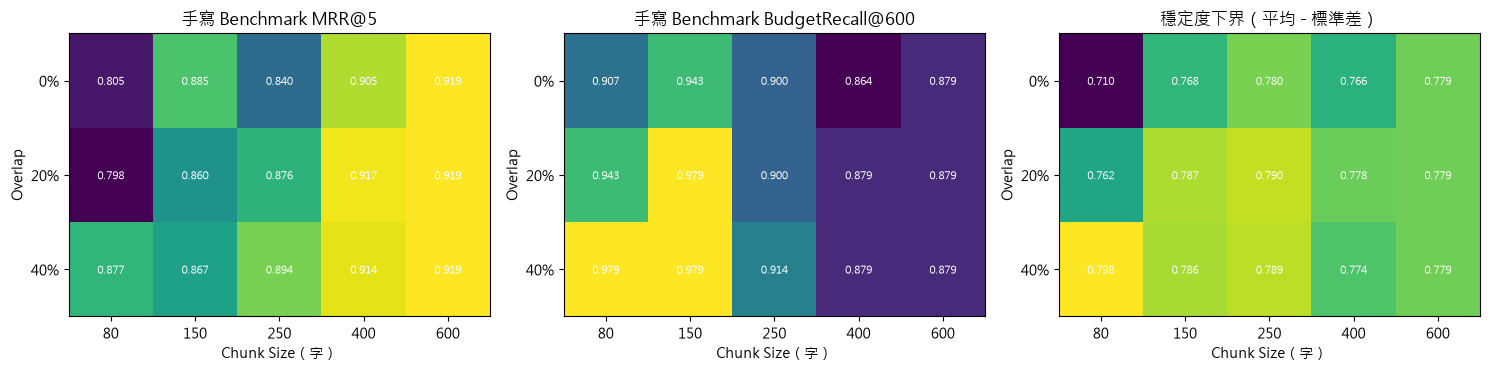

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, title in zip(axes, ["MRR5_hand", "BR600_hand", "stable_LB"], ["手寫 Benchmark MRR@5", "手寫 Benchmark BudgetRecall@600", "穩定度下界（平均 - 標準差）"]):
    pv = grid.pivot(index="overlap_ratio", columns="chunk_size", values=col)
    im = ax.imshow(pv.values, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(pv.columns))); ax.set_xticklabels(pv.columns)
    ax.set_yticks(range(len(pv.index))); ax.set_yticklabels([f"{int(v*100)}%" for v in pv.index])
    ax.set_xlabel("Chunk Size（字）"); ax.set_ylabel("Overlap"); ax.set_title(title)
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]): ax.text(j, i, f"{pv.values[i, j]:.3f}", ha="center", va="center", color="w", fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "hw1_chunk_grid.png", dpi=130); plt.show()

### 1.5.1 Top-K：檢索面（最佳 chunk 設定、Hybrid + Re-Ranker）

,K,Recall,Precision,Recall_std_by_cat,平均context字數
0,1,0.9095,0.9286,0.0705,49.9286
1,2,0.9643,0.8929,0.0411,125.9714
2,3,0.9643,0.7000,0.0411,196.3714
3,5,0.9857,0.4371,0.0164,333.5286
4,8,0.9857,0.2768,0.0164,528.0571


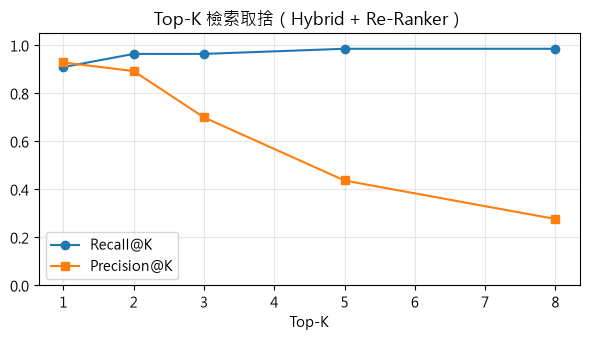

In [12]:
retr_best = Retriever(chunk_corpus(BEST_SIZE, BEST_OV))
KS = [1, 2, 3, 5, 8]
def ranked_for(R, q, rerank=True, mode="hybrid", n=20):
    c = R.search(q, k=n, mode=mode)
    if rerank:
        s = rr.score(q, [passage_text(p) for p in c]); c = [c[i] for i in np.argsort(-s)]
    return dedup_passages(c)

rows = []
for x in hand_items:
    rk = ranked_for(retr_best, x["question"])
    rows.append(retrieval_metrics(rk, x["gold"], ks=KS) | {"category": x["category"]})
topk_df = pd.DataFrame(rows)
topk_tab = pd.DataFrame([dict(K=k, Recall=topk_df[f"Recall@{k}"].mean(), Precision=topk_df[f"P@{k}"].mean(),
                              Recall_std_by_cat=topk_df.groupby("category")[f"Recall@{k}"].mean().std(),
                              平均context字數=topk_df[f"Chars@{k}"].mean()) for k in KS])
display(topk_tab.round(4))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(KS, topk_tab.Recall, "o-", label="Recall@K"); ax.plot(KS, topk_tab.Precision, "s-", label="Precision@K")
ax.set_xlabel("Top-K"); ax.set_ylim(0, 1.05); ax.legend(); ax.set_title("Top-K 檢索取捨（Hybrid + Re-Ranker）"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / "hw1_topk_retrieval.png", dpi=130); plt.show()

### 1.5.2 RAGAS 風格評估工具（作業三沿用）與 Top-K 生成實驗

評估工具以本機 Qwen2.5-3B 當 Judge，依 RAGAS 論文的定義實作（細節見作業三）：
- **Faithfulness：** 拆解回答成陳述 → 逐一判斷是否被 context 支持。
- **Answer Relevance：** 由回答反推 3 個問題，與原問題的 embedding cosine 平均；婉拒回答記 0。
- **Context Relevance：** context 句子中「回答必須用到」的句子比例。
- **Answer Correctness：** 與知識庫標準事實比較，1~5 分換算成 0~1。
- **Context Recall / Precision（有標註正解才能算）：** 正解事實被涵蓋比例 / RAGAS 排名加權精確度。

In [13]:
JUDGE_SYS = "你是嚴謹、公正的 RAG 系統評估員。只輸出要求的 JSON。"
def split_sents(text):
    return [s.strip() for s in re.split(r"(?<=[。！？；!?;])|\n", text) if len(s.strip()) >= 4]

def p_statements(q, a):
    return msgs(JUDGE_SYS, f"請把「回答」拆解成數個獨立、可驗證的事實陳述，每個陳述一句話，忽略客套話與引用編號。只輸出 JSON 字串陣列。\n問題：{q}\n回答：{a}")
def p_verify(ctx, stmts):
    s = "\n".join(f"{i+1}. {x}" for i, x in enumerate(stmts))
    return msgs(JUDGE_SYS, f"以下是參考資料與一組陳述。請逐一判斷每個陳述能否直接由參考資料推論得到（可以=1，不行或資料沒提到=0）。\n輸出 JSON 陣列，例如 [{{\"id\": 1, \"verdict\": 1}}, ...]。\n\n參考資料：\n{ctx}\n\n陳述：\n{s}")
def p_genq(a):
    return msgs(JUDGE_SYS, f"根據下面的回答，推測使用者原本可能問了哪 3 個問題。只輸出 JSON 字串陣列。\n回答：{a}")
def p_ctxrel(q, sents):
    s = "\n".join(f"{i+1}. {x}" for i, x in enumerate(sents))
    return msgs(JUDGE_SYS, f"下面是使用者問題與參考資料的編號句子。請找出「回答這個問題必須用到」的句子編號，輸出 JSON 整數陣列；若都無關請輸出 []。\n問題：{q}\n句子：\n{s}")
def p_correct(q, a, ref):
    return msgs(JUDGE_SYS, f"""請比較「模型回答」與「標準答案」，評估回答是否正確回答了問題。
評分：5=完整且正確；4=大致正確但略有缺漏；3=部分正確；2=大多不正確或答非所問；1=錯誤或與標準答案矛盾。
若標準答案為「應婉拒」，則回答有婉拒或表示無相關資訊得 5 分，否則 1 分。
只輸出 JSON：{{"score": 整數, "reason": "一句話理由"}}

問題：{q}
標準答案：{ref}
模型回答：{a}""")

def ragas_eval(items, judge_bs=16, desc="RAGAS"):
    """items: dict(question, answer, contexts[list[str]], gold[list[fid]], passages(optional), refused)"""
    L = get_llm()
    # 1) Faithfulness step 1 + Answer relevance + Correctness + Context relevance（同批次）
    need_f = [i for i, x in enumerate(items) if x["contexts"] and not x["refused"]]
    st_out = dict(zip(need_f, L.chat([p_statements(items[i]["question"], items[i]["answer"]) for i in need_f], max_new_tokens=300, bs=judge_bs, desc=desc + "-stmt")))
    need_ar = [i for i, x in enumerate(items) if not x["refused"]]
    gq_out = dict(zip(need_ar, L.chat([p_genq(items[i]["answer"]) for i in need_ar], max_new_tokens=160, bs=judge_bs, desc=desc + "-genq")))
    refs = ["；".join(FACTS[f]["text"] for f in x["gold"]) if x["gold"] else "應婉拒（問題不在衣物洗護知識範圍內）" for x in items]
    co_out = L.chat([p_correct(x["question"], x["answer"], r) for x, r in zip(items, refs)], max_new_tokens=100, bs=judge_bs, desc=desc + "-correct")
    sents = {i: split_sents("\n".join(x["contexts"]))[:40] for i, x in enumerate(items) if x["contexts"]}
    cr_out = dict(zip(sents, L.chat([p_ctxrel(items[i]["question"], s) for i, s in sents.items()], max_new_tokens=80, bs=judge_bs, desc=desc + "-ctxrel")))
    # 2) Faithfulness step 2
    stmts = {}
    for i, o in st_out.items():
        s = [x for x in (parse_json(o, []) or []) if isinstance(x, str) and x.strip()][:12]
        if s: stmts[i] = s
    ve_out = dict(zip(stmts, L.chat([p_verify("\n".join(items[i]["contexts"]), s) for i, s in stmts.items()], max_new_tokens=300, bs=judge_bs, desc=desc + "-verify")))
    # 3) 計分
    rows = []
    for i, x in enumerate(items):
        r = dict()
        if i in ve_out:
            v = parse_json(ve_out[i], []) or []
            vd = {int(e.get("id", j + 1)): int(bool(e.get("verdict", 0))) for j, e in enumerate(v) if isinstance(e, dict)}
            r["faithfulness"] = np.mean([vd.get(j + 1, 0) for j in range(len(stmts[i]))])
        else:
            r["faithfulness"] = np.nan
        if x["refused"]:
            r["answer_relevance"] = 0.0 if x["gold"] else np.nan
        else:
            gqs = [g for g in (parse_json(gq_out[i], []) or []) if isinstance(g, str)][:3]
            r["answer_relevance"] = float(np.mean(emb.encode(gqs) @ emb.encode([x.get("ref_question", x["question"])])[0])) if gqs else 0.0
        if i in cr_out:
            sel = {int(s) for s in (parse_json(cr_out[i], []) or []) if isinstance(s, (int, float)) or (isinstance(s, str) and s.isdigit())}
            r["context_relevance"] = len([s for s in sel if 1 <= s <= len(sents[i])]) / max(1, len(sents[i]))
        else:
            r["context_relevance"] = np.nan
        js = parse_json(co_out[i], {}) or {}
        sc = js.get("score") if isinstance(js, dict) else None
        r["correctness"] = (min(5, max(1, int(sc))) - 1) / 4 if isinstance(sc, (int, float)) else np.nan
        if x["gold"] and x.get("passages") is not None:
            ps = x["passages"]; g = set(x["gold"])
            r["context_recall"] = len(set().union(*[p["facts"] for p in ps]) & g) / len(g) if ps else 0.0
            rel = [bool(p["facts"] & g) for p in ps]
            r["context_precision"] = (sum(np.mean(rel[:k + 1]) for k in range(len(rel)) if rel[k]) / max(1, sum(rel))) if ps else 0.0
        rows.append(r)
    return pd.DataFrame(rows)

def to_eval_item(o, question, gold, ref_question=None):
    ps = None if o.get("no_retrieval") else o["passages"]
    return dict(question=question, ref_question=ref_question or question, answer=o["answer"],
                contexts=[passage_text(p) for p in (ps or [])], passages=ps, gold=gold, refused=o["refused"])

def run_system(bot, singles, dialogs):
    """單輪題一次批次；多輪對話則把所有對話的第 t 輪放同一批（保留各自的歷史）。"""
    items, meta = [], []
    outs = bot.answer_batch([[] for _ in singles], [x["question"] for x in singles]) if singles else []
    for x, o in zip(singles, outs):
        items.append(to_eval_item(o, x["question"], x["gold"])); meta.append(dict(id=x["qid"], set="範圍外" if not x["gold"] else "單輪", out=o))
    hist, res = {d["did"]: [] for d in dialogs}, {d["did"]: [] for d in dialogs}
    for ti in range(max((len(d["turns"]) for d in dialogs), default=0)):
        ds = [d for d in dialogs if ti < len(d["turns"])]
        outs = bot.answer_batch([hist[d["did"]] for d in ds], [d["turns"][ti]["q"] for d in ds])
        for d, o in zip(ds, outs):
            hist[d["did"]].append(dict(user=d["turns"][ti]["q"], bot=o["answer"])); res[d["did"]].append(o)
    for d in dialogs:
        for ti, (o, t) in enumerate(zip(res[d["did"]], d["turns"])):
            ref_q = " / ".join([tt["q"] for tt in d["turns"][:ti + 1]])
            items.append(to_eval_item(o, t["q"], t["gold"], ref_question=ref_q)); meta.append(dict(id=f"{d['did']}-{ti+1}", set="多輪", out=o))
    return items, meta

In [14]:
# Top-K 對生成品質的影響（手寫單輪題的分層子集，G2 prompt）
k_items = ST_IN[::2] if not QUICK else ST_IN[:8]
K_GEN = [1, 3, 5, 8]
k_rows = []
for k in K_GEN:
    bot = CareRAG(retr_best, k=k, technique="rewrite", gen_style="G2-嚴格依據+引用", tau=TAU)
    items, meta = run_system(bot, k_items, [])
    ev = ragas_eval(items, desc=f"K{k}")
    k_rows.append(dict(K=k, **ev.mean(numeric_only=True).to_dict(), 平均context字數=np.mean([sum(len(c) for c in it["contexts"]) for it in items])))
k_gen = pd.DataFrame(k_rows); k_gen.to_csv(OUT / f"{sfx('hw1_topk_generation')}.csv", index=False)
display(k_gen.round(4))
k_gen["綜合"] = k_gen[["faithfulness", "correctness", "answer_relevance"]].mean(axis=1)
BEST_K = int(k_gen.sort_values(["綜合", "K"], ascending=[False, True]).iloc[0].K)
print("Top-K 選擇：", BEST_K)

,K,faithfulness,answer_relevance,context_relevance,correctness,context_recall,context_precision,平均context字數
0,1,0.8697,0.2420,0.7429,0.2929,0.8905,0.9143,54.3714
1,3,0.9461,0.3774,0.1020,0.4118,0.9714,0.9405,217.4000
2,5,0.9632,0.4674,0.1618,0.5357,0.9714,0.9381,373.7143
3,8,0.9171,0.5721,0.1276,0.5786,0.9714,0.9321,597.0286


Top-K 選擇： 8


## 1.6 進階：找出最合適的 Prompting Technique

分兩部分比較：

**(A) Query 轉換技術（影響檢索）**：在 16 段多輪對話（48 輪）與 70 題單輪題上量測 MRR@5 / Recall@K。

| 代號 | 技術 | 說明 |
|---|---|---|
| raw | 原句 | 直接用使用者當下這句話檢索 |
| concat | 串接歷史 | 把前兩輪使用者發言串在一起 |
| rewrite | Query Rewriting | LLM 補齊代名詞、改成完整問句 |
| multiquery | Rewriting + Multi-Query | 再生成 3 種問法，RRF 融合 |
| stepback | Rewriting + Step-Back | 加入抽象化的背景問題一起檢索 |
| hyde | Rewriting + HyDE | 先讓 LLM 寫假想答案，用答案向量檢索 |

**(B) 生成 Prompt（影響回答）**：G1 基本 / G2 嚴格依據+引用 / G3 加單例示範 / G4 Self-RAG 式先反思再回答，以 RAGAS 指標、引用正確率與範圍外婉拒率比較。

In [15]:
TECHS = ["raw", "concat", "rewrite", "multiquery", "stepback", "hyde"]
def eval_technique(tech, rerank=True):
    bot = CareRAG(retr_best, k=BEST_K, technique=tech, rerank=rerank, tau=TAU)
    rows = []
    # 多輪：歷史只給使用者發言（避免與生成結果耦合），所有對話的同一輪一起批次改寫
    hs, us, tags = [], [], []
    for d in MT:
        for ti, t in enumerate(d["turns"]):
            hs.append([dict(user=tt["q"], bot="") for tt in d["turns"][:ti]]); us.append(t["q"]); tags.append(("多輪", ti + 1, t["gold"]))
    for x in ST_IN:
        hs.append([]); us.append(x["question"]); tags.append(("單輪", 1, x["gold"]))
    for (q, qs), (s, ti, gold) in zip(bot.transform_batch(hs, us), tags):
        cands, _ = bot.retrieve(q, qs)
        rows.append(retrieval_metrics(dedup_passages(cands), gold) | dict(set=s, turn=ti, query=q))
    return pd.DataFrame(rows)

tech_res = {t: eval_technique(t) for t in tqdm(TECHS, desc="techniques")}
tech_res["rewrite（無 Re-Ranker）"] = eval_technique("rewrite", rerank=False)
tab = []
for t, df in tech_res.items():
    mt, st = df[df.set == "多輪"], df[df.set == "單輪"]
    tab.append({"技術": t, "多輪 MRR@5": mt["MRR@5"].mean(), "多輪 第2-3輪 MRR@5": mt[mt.turn > 1]["MRR@5"].mean(),
                f"多輪 Recall@{BEST_K}": mt[f"Recall@{BEST_K}"].mean(),
                "單輪 MRR@5": st["MRR@5"].mean(), "整體 MRR@5": df["MRR@5"].mean()})
tech_tab = pd.DataFrame(tab); tech_tab.to_csv(OUT / f"{sfx('hw1_query_techniques')}.csv", index=False)
display(tech_tab.round(4))
ex = pd.DataFrame({t: tech_res[t][tech_res[t].set == "多輪"]["query"].values for t in ["raw", "rewrite", "stepback"]}).head(9)
display(ex)


techniques:   0%|          | 0/6 [00:00<?, ?it/s]


techniques:  17%|█▋        | 1/6 [00:03<00:16,  3.29s/it]


techniques:  33%|███▎      | 2/6 [00:05<00:11,  2.87s/it]


techniques:  50%|█████     | 3/6 [00:07<00:07,  2.52s/it]


techniques:  67%|██████▋   | 4/6 [00:10<00:05,  2.63s/it]


techniques:  83%|████████▎ | 5/6 [00:13<00:02,  2.82s/it]


techniques: 100%|██████████| 6/6 [00:15<00:00,  2.54s/it]


techniques: 100%|██████████| 6/6 [00:15<00:00,  2.65s/it]

,技術,多輪 MRR@5,多輪 第2-3輪 MRR@5,多輪 Recall@8,單輪 MRR@5,整體 MRR@5
0,raw,0.5681,0.3990,0.8368,0.9536,0.7968
1,concat,0.7663,0.6964,0.9549,0.9536,0.8774
2,rewrite,0.7733,0.7068,0.9132,0.9536,0.8802
3,multiquery,0.7566,0.6818,0.8924,0.9557,0.8747
4,stepback,0.7431,0.7396,0.8299,0.9500,0.8658
5,hyde,0.7743,0.7083,0.9062,0.9576,0.8831
6,rewrite（無 Re-Ranker）,0.6920,0.6604,0.8750,0.8886,0.8086


,raw,rewrite,stepback
0,我有一件羊毛大衣想自己洗,我有一件羊毛大衣想自己洗,我有一件羊毛大衣想自己洗
1,那它可以用洗衣機烘乾嗎？,那件羊毛大衣可以用洗衣機烘乾嗎？,那件羊毛大衣可以用洗衣機烘乾嗎？
2,洗完要怎麼晾？,洗完之後該如何晾乾這件羊毛大衣？,洗完之後該如何晾乾這件羊毛大衣？
3,洗標上有一個三角形裡面兩條斜線,洗標上有一個三角形裡面兩條斜線,洗標上有一個三角形裡面兩條斜線
4,所以我家那瓶漂白水不能用囉？,我家那瓶漂白水是否可以使用？,我家那瓶漂白水是否可以使用？
5,那可以改用什麼？,那可以改用什麼漂白水？,那可以改用什麼漂白水？
6,我的白襯衫沾到咖啡,我的白襯衫沾到咖啡,我的白襯衫沾到咖啡
7,已經過了一天了還洗得掉嗎？,如何在一天後清洗沾上咖啡的白色襯衫？,如何在一天後清洗沾上咖啡的白色襯衫？
8,可以先丟烘衣機嗎？,如何處理已經沾上咖啡的白襯衫，是否可以在不先洗的狀況下先使用烘衣機？,如何處理已經沾上咖啡的白襯衫，是否可以在不先洗的狀況下先使用烘衣機？


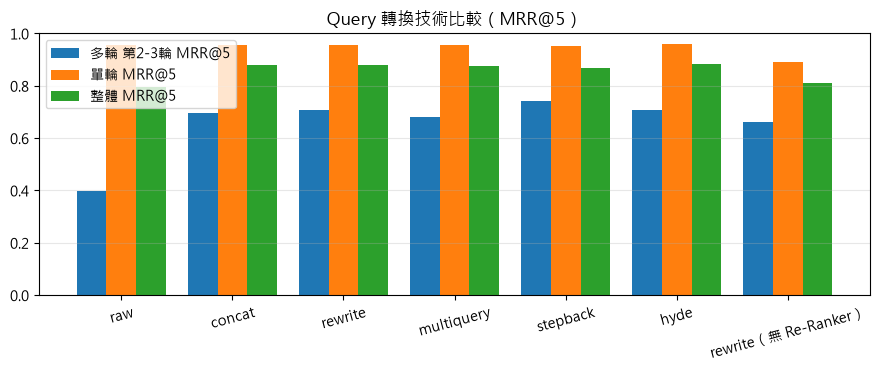

最佳 Query 技術： hyde


In [16]:
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(tech_tab)); w = .27
for j, col in enumerate(["多輪 第2-3輪 MRR@5", "單輪 MRR@5", "整體 MRR@5"]):
    ax.bar(x + (j - 1) * w, tech_tab[col], w, label=col)
ax.set_xticks(x); ax.set_xticklabels(tech_tab["技術"], rotation=15); ax.set_ylim(0, 1); ax.legend(); ax.grid(axis="y", alpha=.3)
ax.set_title("Query 轉換技術比較（MRR@5）")
plt.tight_layout(); plt.savefig(OUT / "hw1_query_techniques.png", dpi=130); plt.show()
best_tech_row = tech_tab[tech_tab["技術"].isin(TECHS)].sort_values("整體 MRR@5", ascending=False).iloc[0]
BEST_TECH = best_tech_row["技術"]
print("最佳 Query 技術：", BEST_TECH)

In [17]:
# (B) 生成 Prompt 比較：多輪對話全部 + 單輪分層子集 + 範圍外題
gp_single = (ST_IN[1::3] if not QUICK else ST_IN[:6]) + ST_OOS
gp_dialogs = MT if not QUICK else MT[:3]

def citation_stats(items, meta):
    has, prec = [], []
    for it, m in zip(items, meta):
        if it["refused"] or not it["gold"] or not it["passages"]: continue
        c = cited_ids(it["answer"], len(it["passages"]))
        has.append(bool(c))
        if c: prec.append(np.mean([bool(it["passages"][i - 1]["facts"] & set(it["gold"])) for i in c]))
    return dict(有引用比例=np.mean(has) if has else np.nan, 引用正確率=np.mean(prec) if prec else np.nan)

gp_rows, GP_RESULTS = [], {}
for style in GEN_PROMPTS:
    bot = CareRAG(retr_best, k=BEST_K, technique=BEST_TECH, gen_style=style, tau=TAU)
    items, meta = run_system(bot, gp_single, gp_dialogs)
    ev = ragas_eval(items, desc=style[:2])
    sets = np.array([m["set"] for m in meta])
    oos = np.array([it["refused"] for it in items])[sets == "範圍外"]
    false_ref = np.array([it["refused"] for it in items])[sets != "範圍外"]
    GP_RESULTS[style] = (items, meta, ev)
    gp_rows.append(dict(Prompt=style, **ev[sets != "範圍外"].mean(numeric_only=True).to_dict(), **citation_stats(items, meta),
                        範圍外婉拒率=oos.mean(), 誤拒率=false_ref.mean(), 平均回答字數=np.mean([len(it["answer"]) for it in items])))
gp_tab = pd.DataFrame(gp_rows); gp_tab.to_csv(OUT / f"{sfx('hw1_gen_prompts')}.csv", index=False)
display(gp_tab.round(4))
gp_tab["綜合"] = gp_tab[["faithfulness", "answer_relevance", "correctness", "有引用比例"]].fillna(0).mean(axis=1)
display(gp_tab[["Prompt", "綜合"]].round(4))
BEST_GEN = gp_tab.sort_values("綜合", ascending=False).iloc[0]["Prompt"]
print("最佳生成 Prompt：", BEST_GEN)

,Prompt,faithfulness,answer_relevance,context_relevance,correctness,context_recall,context_precision,有引用比例,引用正確率,範圍外婉拒率,誤拒率,平均回答字數
0,G1-基本,0.7810,0.7082,0.1388,0.5986,0.9085,0.8047,0.0147,1.0000,1.0,0.0423,219.5467
1,G2-嚴格依據+引用,0.8724,0.5184,0.1388,0.4859,0.9085,0.8047,0.8958,0.7500,1.0,0.3239,54.8667
2,G3-嚴格+單例示範,0.7997,0.5974,0.1388,0.5704,0.9085,0.8047,1.0000,0.6874,1.0,0.1268,57.9467
3,G4-先反思再回答,0.7698,0.6781,0.1388,0.6690,0.9085,0.8047,0.9552,0.6404,1.0,0.0563,78.7733


,Prompt,綜合
0,G1-基本,0.5256
1,G2-嚴格依據+引用,0.6931
2,G3-嚴格+單例示範,0.7419
3,G4-先反思再回答,0.7680


最佳生成 Prompt： G4-先反思再回答


## 1.7 最終系統設定

In [18]:
FINAL = dict(chunk_size=BEST_SIZE, overlap=BEST_OV, top_k=BEST_K, technique=BEST_TECH, gen_prompt=BEST_GEN,
             rerank=True, gate_tau=round(TAU, 4), retrieval="hybrid (chunk + QA, RRF) → bge-reranker-v2-m3")
json.dump(FINAL, open(OUT / "hw1_final_config.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
final_bot = CareRAG(retr_best, k=BEST_K, technique=BEST_TECH, gen_style=BEST_GEN, tau=TAU)
n_emb = dict(QA_問題向量=len(QA), Chunk向量=len(retr_best.chunks), 事實段落=len(FACT_PASSAGES))
display(pd.DataFrame([FINAL])); display(pd.DataFrame([n_emb | {"合計 Embedding": sum(n_emb.values())}]))

,chunk_size,overlap,top_k,technique,gen_prompt,rerank,gate_tau,retrieval
0,80,32,8,hyde,G4-先反思再回答,True,0.0262,"hybrid (chunk + QA, RRF) → bge-reranker-v2-m3"


,QA_問題向量,Chunk向量,事實段落,合計 Embedding
0,1050,161,210,1421


## 1.8 進階：User Interface（Gradio）

- 左側為多輪聊天室，右側即時顯示 **改寫後的檢索查詢** 與 **Reference**（✅ 表示回答中有引用，附文件名稱、段落座標與 fact id）。
- 「檢索設定」可即時切換 Query 技術、Top-K、Re-Ranker，方便展示不同設定的差異。
- 設 `W10_LAUNCH_UI=0` 可在批次執行時不啟動。

In [19]:
import gradio as gr

def build_ui():
    with gr.Blocks(title="洗標小幫手 RAG", theme=gr.themes.Soft()) as demo:
        gr.Markdown("## 🧺 洗標小幫手｜多輪對話 RAG\n只回答衣物洗護與洗標符號問題；每個回答都附上知識庫 Reference。")
        sess = gr.State([])
        with gr.Row():
            with gr.Column(scale=3):
                chat = gr.Chatbot(type="messages", height=480, label="對話")
                box = gr.Textbox(placeholder="例如：羊毛衣可以丟洗衣機嗎？", label="輸入問題", lines=1)
                with gr.Row():
                    send = gr.Button("送出", variant="primary"); clear = gr.Button("清除對話")
                gr.Examples(["洗標上水盆裡有一隻手是什麼意思？", "我有一件羊毛大衣想自己洗", "那它可以用洗衣機烘乾嗎？", "衣服沾到紅酒怎麼辦？"], inputs=box)
            with gr.Column(scale=2):
                q_box = gr.Textbox(label="🔎 改寫後的檢索查詢", interactive=False)
                ref_md = gr.Markdown("**📚 Reference**")
                with gr.Accordion("⚙️ 檢索設定", open=False):
                    tech = gr.Dropdown(TECHS, value=BEST_TECH, label="Query 技術")
                    topk = gr.Slider(1, 8, value=BEST_K, step=1, label="Top-K")
                    use_rr = gr.Checkbox(True, label="使用 Re-Ranker 與閘門")
        def respond(text, history, sess, tech, topk, use_rr):
            if not text.strip(): return "", history, sess, gr.update(), gr.update()
            bot = CareRAG(retr_best, k=int(topk), technique=tech, gen_style=BEST_GEN, rerank=use_rr, gate=use_rr, tau=TAU)
            o = bot.answer(sess, text)
            sess = sess + [dict(user=text, bot=o["answer"])]
            history = history + [{"role": "user", "content": text}, {"role": "assistant", "content": o["answer"]}]
            refs = "**📚 Reference**\n\n" + "\n\n".join(format_refs(o).split("\n")) + f"\n\n<sub>最高 re-rank 分數 {o['max_score']:.3f}｜延遲 {o['latency']:.1f}s</sub>"
            return "", history, sess, o["query"], refs
        ins = [box, chat, sess, tech, topk, use_rr]; outs = [box, chat, sess, q_box, ref_md]
        send.click(respond, ins, outs); box.submit(respond, ins, outs)
        clear.click(lambda: ([], [], "", "**📚 Reference**"), None, [chat, sess, q_box, ref_md])
    return demo

ui = build_ui()
if LAUNCH_UI:
    ui.launch(server_name="127.0.0.1", server_port=7860, prevent_thread_lock=True, inbrowser=False)
else:
    print("W10_LAUNCH_UI=0：略過啟動 Gradio（介面已建立，可執行 ui.launch() 開啟）")

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


---
# 作業二：多輪對話 VideoRAG

> 兩支自錄影片：`care_label`（翻看 T 恤洗標並口頭講解，speech）與 `dryer_coin`（自助洗衣店烘衣機投幣與設定，silent）。影片放在 `data/videos/`（已 gitignore）

**參考 VideoRAG 並改編：**

| 論文元件 | 本作業實作 |
|---|---|
| 影格 1 fps 取樣 + CLIP 特徵 | PyAV 解碼 1 fps，CLIP ViT-B/32 影像特徵 |
| k-means++ 縮小搜尋空間（檢索 8 選 4、生成 64 選 32） | k-means++ 取最接近群中心的影格；檢索 8 選 4；生成 64 候選中選 m=8（3060 顯存限制，論文為 32） |
| 檢索用 frame selection f(V′) | 無訓練資料時以「覆蓋度」（facility location）挑最具代表性的 4 張；可選用論文的自動標註 + 3 層 MLP 訓練 |
| 生成用 frame selection f(V′, q)：隨機抽 40 組 | 隨機抽 40 組，以「影格平均向量 · 查詢向量」打分（論文在 CLIP 上再加 3 層 MLP） |
| 無字幕時用 Whisper ASR 產生輔助文字 | Whisper-small ASR（含時間戳）；**無聲操作影片改用 Qwen2-VL 生成影格描述**作為輔助文字 |
| f_video = α·F_text + (1−α)·F_visual | 分數層級融合：α·z(文字分數) + (1−α)·z(CLIP 視覺分數)，α=0.6（論文最佳 0.5~0.7） |
| LVLM 生成 [V, t, q] | Qwen2-VL-2B：選出的影格（附時間戳）+ 相關逐字稿片段 + 改寫後的問題（多輪脈絡只用於改寫，避免 2B 模型照抄上一輪回答） |

## 2.1 影片語料庫

In [20]:
VIDEO_DIR = Path(os.environ.get("W10_VIDEO_DIR", DATA / "videos"))
VCACHE = Path(os.environ.get("W10_VIDEO_CACHE", DATA / "video_cache"))
VIDEO_EXTS = {".mp4", ".mov", ".mkv", ".avi", ".webm", ".m4v"}
video_files = sorted(p for p in VIDEO_DIR.glob("*") if p.suffix.lower() in VIDEO_EXTS) if VIDEO_DIR.exists() else []
meta_csv = VIDEO_DIR / "videos.csv"
VMETA = {}
if meta_csv.exists():
    for r in pd.read_csv(meta_csv).to_dict("records"): VMETA[str(r["file"])] = r
def _cell(r, k, default=""):
    v = r.get(k, default)
    return default if v is None or (isinstance(v, float) and math.isnan(v)) else str(v).strip()
VIDEOS = [dict(video_id=_cell(VMETA.get(p.name, {}), "video_id", p.stem), file=p, title=_cell(VMETA.get(p.name, {}), "title", p.stem),
               kind_hint=_cell(VMETA.get(p.name, {}), "kind")) for p in video_files]
HAS_VIDEO = len(VIDEOS) > 0
VR = dict(fps=1.0, short_side=336, k_ret=8, m_ret=4, k_gen=64, m_gen=8, n_samples=40, alpha=0.6, cap_every=2, max_caps=60)
if HAS_VIDEO:
    display(pd.DataFrame([dict(video_id=v["video_id"], file=v["file"].name, title=v["title"], kind=v["kind_hint"]) for v in VIDEOS]))
else:
    print(f"⚠️ {VIDEO_DIR} 尚無影片：作業二與 3.5 只定義管線、不執行。請依 data/videos/README.md 放入自錄影片後重跑。")

,video_id,file,title,kind
0,dryer_coin,be3d674d-127e-4287-8b1a-379800d80bf4.mp4,自助洗衣店烘衣機投幣與設定（無聲操作）,silent
1,care_label,e6fb0cb2-7b64-42f1-8283-65573e14d2b2.mp4,看懂T恤洗標：棉與聚酯纖維混紡（口頭講解）,speech


## 2.2 前處理：1 fps 影格、音訊 → Whisper ASR、無聲偵測

In [21]:
import av
from PIL import Image

def extract_frames(path, fps=1.0, short_side=336):
    frames, ts = [], []
    with av.open(str(path)) as c:
        st = c.streams.video[0]; st.thread_type = "AUTO"; nxt = 0.0
        for fr in c.decode(st):
            t = float(fr.pts * st.time_base) if fr.pts is not None else float(fr.time or 0)
            if t + 1e-6 < nxt: continue
            img = fr.to_image().convert("RGB"); w, h = img.size; s = short_side / min(w, h)
            frames.append(img.resize((max(1, int(w * s)), max(1, int(h * s))))); ts.append(round(t, 2)); nxt += 1 / fps
    return frames, ts

def extract_audio(path, sr=16000):
    with av.open(str(path)) as c:
        if not c.streams.audio: return None
        res = av.AudioResampler(format="flt", layout="mono", rate=sr); chunks = []
        for fr in c.decode(audio=0):
            for r in res.resample(fr): chunks.append(r.to_ndarray().reshape(-1))
        for r in res.resample(None): chunks.append(r.to_ndarray().reshape(-1))
    return np.concatenate(chunks).astype(np.float32) if chunks else None

def voiced_ratio(audio, sr=16000, win=0.03):
    if audio is None or len(audio) < sr: return 0.0
    n = int(sr * win); a = audio[: len(audio) // n * n].reshape(-1, n)
    rms = np.sqrt((a ** 2).mean(1) + 1e-12); thr = max(0.01, np.percentile(rms, 20) * 4)
    return float((rms > thr).mean())

_ASR = None
def asr_transcribe(audio, sr=16000):
    global _ASR
    from transformers import pipeline
    if _ASR is None:
        _ASR = pipeline("automatic-speech-recognition", model=CONFIG["asr"], dtype=torch.float16, device=0)
    out = _ASR({"raw": audio, "sampling_rate": sr}, return_timestamps=True, chunk_length_s=30, batch_size=8,
               generate_kwargs={"language": "zh", "task": "transcribe"})
    dur = len(audio) / sr
    return [dict(start=float(c["timestamp"][0] or 0), end=float(c["timestamp"][1] or dur), text=c["text"].strip(), src="asr")
            for c in out.get("chunks", []) if c["text"].strip()]

## 2.3 CLIP 影格特徵、k-means++ 候選影格與 Frame Selection

In [22]:
from sklearn.cluster import KMeans
from transformers import CLIPModel, CLIPProcessor

_CLIP = None
def get_clip():
    global _CLIP
    if _CLIP is None:
        _CLIP = (CLIPModel.from_pretrained(CONFIG["clip"], dtype=torch.float16).to(DEVICE).eval(), CLIPProcessor.from_pretrained(CONFIG["clip"]))
    return _CLIP

def _feat(e): return e if torch.is_tensor(e) else (e.pooler_output if hasattr(e, "pooler_output") else e[0])

@torch.inference_mode()
def clip_images(imgs, bs=32):
    m, p = get_clip(); out = []
    for i in range(0, len(imgs), bs):
        px = p(images=imgs[i:i + bs], return_tensors="pt")["pixel_values"].to(DEVICE, torch.float16)
        out.append(torch.nn.functional.normalize(_feat(m.get_image_features(pixel_values=px)).float(), dim=-1).cpu().numpy())
    return np.concatenate(out)

@torch.inference_mode()
def clip_text(texts):
    m, p = get_clip()
    enc = p(text=texts, return_tensors="pt", padding=True, truncation=True, max_length=77).to(DEVICE)
    return torch.nn.functional.normalize(_feat(m.get_text_features(**enc)).float(), dim=-1).cpu().numpy()

def kmeans_candidates(E, k):
    """k-means++ 分群，每群取最接近群中心的影格（依時間排序）— 論文的 Frame Space Reduction。"""
    if len(E) <= k: return list(range(len(E)))
    km = KMeans(n_clusters=k, init="k-means++", n_init=3, random_state=SEED).fit(E)
    idx = [int(np.argmin(((E - c) ** 2).sum(1) + (km.labels_ != j) * 1e9)) for j, c in enumerate(km.cluster_centers_)]
    return sorted(set(idx))

def select_retrieval_frames(E, cand, m=4):
    """檢索用（與查詢無關）：在 C(k, m) 組合中挑「覆蓋度」最高的一組 = 所有影格到最近已選影格的平均相似度。"""
    if len(cand) <= m: return list(cand)
    best, best_s = None, -1
    for sub in itertools.combinations(cand, m):
        s = (E @ E[list(sub)].T).max(1).mean()
        if s > best_s: best, best_s = list(sub), s
    return best

class FrameScorer(torch.nn.Module):
    """論文 A.3：CLIP 特徵上的 3 層 MLP；生成時 score = mean(MLP(frames)) · MLP_q(query)。"""
    def __init__(self, d=512, h=512):
        super().__init__()
        mk = lambda: torch.nn.Sequential(torch.nn.Linear(d, h), torch.nn.ReLU(), torch.nn.Linear(h, h), torch.nn.ReLU(), torch.nn.Linear(h, d))
        self.f, self.q = mk(), mk()
    def forward(self, F, q):  # F: (B, m, d), q: (B, d)
        return (torch.nn.functional.normalize(self.f(F).mean(1), dim=-1) * torch.nn.functional.normalize(self.q(q), dim=-1)).sum(-1)

FRAME_SCORER = None  # 若用 train_frame_scorer() 訓練後指定，生成時改用 MLP 打分

def subset_score(Fs, qv):
    if FRAME_SCORER is not None:
        with torch.no_grad():
            return float(FRAME_SCORER(torch.tensor(Fs[None]).float(), torch.tensor(qv[None]).float())[0])
    v = Fs.mean(0); return float(v @ qv / (np.linalg.norm(v) + 1e-8))

def select_generation_frames(E, cand, qv, m=8, n_samples=40, seed=SEED):
    """生成用（query-guided）：從候選中隨機抽 n_samples 組 m 張，取 f(V′, q) 最高的一組 — 論文的 Adaptive Frame Selection。"""
    cand = list(cand)
    if len(cand) <= m: return cand
    rng = np.random.default_rng(seed); best, best_s = None, -1e9
    for _ in range(n_samples):
        sub = sorted(rng.choice(cand, m, replace=False).tolist()); s = subset_score(E[sub], qv)
        if s > best_s: best, best_s = sub, s
    return best

def uniform_frames(n, m):
    return sorted(set(np.linspace(0, n - 1, min(m, n)).round().astype(int).tolist()))

def train_frame_scorer(videos, queries_per_video, epochs=30, n_sub=30, m=8):
    """依論文 A.3 自動標註：每個 (query, video) 抽 n_sub 組影格，相似度最高 3 組標 True、最低 3 組標 False，以 BCE 訓練 MLP。"""
    X, Q, Y = [], [], []
    for v in videos:
        E = v["clip"]
        for q in queries_per_video.get(v["video_id"], []):
            qv = clip_text([q])[0]; rng = np.random.default_rng(SEED)
            subs = [sorted(rng.choice(v["gen_cands"], min(m, len(v["gen_cands"])), replace=False).tolist()) for _ in range(n_sub)]
            sc = np.array([subset_score(E[s], qv) for s in subs]); o = np.argsort(sc)
            for i, lab in [(i, 1.) for i in o[-3:]] + [(i, 0.) for i in o[:3]]:
                X.append(E[subs[i]]); Q.append(qv); Y.append(lab)
    if not X: return None
    net = FrameScorer(); opt = torch.optim.Adam(net.parameters(), 1e-3)
    X, Q, Y = torch.tensor(np.stack(X)).float(), torch.tensor(np.stack(Q)).float(), torch.tensor(Y)
    for _ in range(epochs):
        loss = torch.nn.functional.binary_cross_entropy_with_logits(net(X, Q) * 10, Y); opt.zero_grad(); loss.backward(); opt.step()
    return net.eval()

## 2.4 VLM（Qwen2-VL-2B）：無聲影片影格描述、查詢改寫與回答生成

In [23]:
from transformers import AutoProcessor, AutoModelForImageTextToText
_VLM = None
def get_vlm():
    global _VLM
    if _VLM is None:
        free_llm()  # 3060 12GB：VideoRAG 階段先釋放文字 LLM
        proc = AutoProcessor.from_pretrained(CONFIG["vlm"], min_pixels=128 * 28 * 28, max_pixels=256 * 28 * 28)
        model = AutoModelForImageTextToText.from_pretrained(CONFIG["vlm"], dtype=torch.bfloat16, device_map={"": 0}, attn_implementation="sdpa").eval()
        _VLM = (model, proc)
    return _VLM
def free_vlm():
    global _VLM
    _VLM = None; gc.collect(); torch.cuda.empty_cache()

@torch.inference_mode()
def vlm_chat(messages, images=None, max_new_tokens=256, repetition_penalty=1.0):
    model, proc = get_vlm()
    text = proc.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = proc(text=[text], images=images or None, return_tensors="pt").to(model.device)
    out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False, repetition_penalty=repetition_penalty)
    return proc.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def vtext(role, text): return {"role": role, "content": [{"type": "text", "text": text}]}

BOILER = re.compile(r"^(在這(張|個|幅)?(圖片|畫面|影像)中[，,]?\s*)")
def trim_sentence(t):
    """截掉被 max_new_tokens 切斷的半句。"""
    k = max(t.rfind("。"), t.rfind("！"), t.rfind("？"))
    return t[:k + 1] if k >= 8 else t

def caption_frames(frames, ts, title=""):
    """無聲影片的主要文字來源：提示影片主題，要求寫出畫面上可讀到的數字／文字與手部動作。"""
    segs = []
    for img, t in zip(frames, ts):
        c = vlm_chat([vtext("system", "你是影片畫面描述員。"),
                      {"role": "user", "content": [{"type": "image"}, {"type": "text", "text":
                       f"這是教學影片「{title}」的一個畫面。用一到兩句繁體中文具體描述：手正在做什麼操作、操作哪個物品或按鍵；"
                       "畫面上看得清楚的數字、文字或符號請照實寫出。不要推測看不到的內容。"}]}],
                     images=[img], max_new_tokens=80, repetition_penalty=1.1)
        segs.append(dict(start=float(t), end=float(t) + 1, text=trim_sentence(BOILER.sub("", c.strip())), src="caption"))
    return segs

def vlm_rewrite(history, user):
    """兩步：(1) 依多輪歷史改寫成完整中文問題（與作業一同一個 prompt）；(2) 翻成英文給 CLIP 文字編碼器。"""
    zh = user
    if history:
        pm = rewrite_prompt([h["user"] for h in history[-3:]], user, [h["bot"] for h in history[-3:]])
        zh = clean_rewrite(re.sub(r"^(最新問題|改寫後的問題)[:：]\s*", "", vlm_chat([vtext(m["role"], m["content"]) for m in pm], max_new_tokens=64).strip()), user)
    en = vlm_chat([vtext("system", "You are a translator."), vtext("user", f"Translate into a short English search query. Output only the translation.\n{zh}")], max_new_tokens=40)
    return zh, en.split("\n")[0].strip() or zh

## 2.5 建立影片 Index 與 VideoRAG 檢索

In [24]:
def preprocess_video(v):
    cdir = VCACHE / v["video_id"]; cdir.mkdir(parents=True, exist_ok=True); mf = cdir / "meta.json"
    frames, ts = extract_frames(v["file"], VR["fps"], VR["short_side"])
    if mf.exists() and not FORCE:
        meta = json.load(open(mf, encoding="utf-8"))
    else:
        audio = extract_audio(v["file"]); vr_ = voiced_ratio(audio)
        segs = asr_transcribe(audio) if (audio is not None and vr_ > 0.08) else []
        kind = v["kind_hint"] or ("speech" if sum(len(s["text"]) for s in segs) >= 10 else "silent")
        meta = dict(video_id=v["video_id"], title=v["title"], duration=float(ts[-1] if ts else 0), n_frames=len(frames), voiced_ratio=vr_, kind=kind, asr=segs)
    E = clip_images(frames)
    meta["ret_cands"] = kmeans_candidates(E, VR["k_ret"]); meta["gen_cands"] = kmeans_candidates(E, VR["k_gen"])
    meta["ret_frames"] = select_retrieval_frames(E, meta["ret_cands"], VR["m_ret"])
    if "captions" not in meta:   # 輔助文字：無聲影片靠影格描述；有聲影片也加上，補足視覺資訊
        cap_idx = sorted(set(meta["ret_cands"]) | set(range(0, len(frames), VR["cap_every"])))[:VR["max_caps"]]
        meta["captions"] = caption_frames([frames[i] for i in cap_idx], [ts[i] for i in cap_idx], v["title"])
    json.dump(meta, open(mf, "w", encoding="utf-8"), ensure_ascii=False, indent=1)
    return dict(**meta, frames=frames, ts=ts, clip=E)

class VideoIndex:
    def __init__(self, vids, alpha=VR["alpha"]):
        self.V, self.alpha = vids, alpha
        self.vis = np.stack([torch.nn.functional.normalize(torch.tensor(v["clip"][v["ret_frames"]].mean(0)), dim=0).numpy() for v in vids])
        self.segs = [[dict(start=0, end=0, text=v["title"], src="title")] + v["asr"] + v["captions"] for v in vids]
        self.seg_E = [emb.encode([s["text"] for s in ss]) for ss in self.segs]
    def search(self, q_zh, q_en, k=1, alpha=None, modality="vt"):
        a = self.alpha if alpha is None else alpha
        qv = emb.encode([q_zh])[0]; cv = clip_text([q_en])[0]
        s_t = np.array([float((E @ qv).max()) for E in self.seg_E]); s_v = self.vis @ cv
        z = lambda x: (x - x.mean()) / (x.std() + 1e-6) if len(x) > 1 else x
        s = {"t": z(s_t), "v": z(s_v), "vt": a * z(s_t) + (1 - a) * z(s_v)}[modality]
        order = np.argsort(-s)[:k]
        return [(self.V[i], float(s[i]), float(s_t[i]), float(s_v[i])) for i in order]
    def top_segments(self, vi, q_zh, n=4):
        E = self.seg_E[vi]; s = E @ emb.encode([q_zh])[0]
        return [self.segs[vi][j] | {"score": float(s[j])} for j in np.argsort(-s)[:n] if self.segs[vi][j]["src"] != "title"]

## 2.6 多輪對話 VideoRAG 聊天機器人

In [25]:
VIDEO_SYS = """你是「洗護影片小幫手」。你會看到從教學影片中挑出的影格（附時間戳）與影片逐字稿／畫面描述。
請只根據影片內容，用繁體中文回答使用者問題，並在句末標註依據的時間點，例如（00:35）。
影片沒有提到的內容請說「影片中沒有相關內容」。"""

def mmss(t): return f"{int(t // 60):02d}:{int(t % 60):02d}"

def clean_video_answer(a, max_sent=4):
    """小型 VLM 容易照抄 context 或重複：移除來源標記、畫面描述開頭語與句首時間，依句去重並限制句數。"""
    a = re.sub(r"\[(語音|畫面)\]\s*|(語音|畫面描述)：", "", a)
    a = re.sub(r"(^|\n)\s*[（(]\d{2}:\d{2}[)）]\s*", r"\1", a)
    a = re.sub(r"(第[一二三四]句|原因或步驟|原因|步驟|步骤|回答)[:：]\s*", "", a)
    sents = [BOILER.sub("", x.strip()) for x in re.split(r"(?<=[。！？])|\n", a) if x and x.strip()]
    sents = [x for x in dict.fromkeys(sents) if len(x) > 1]
    return trim_sentence("".join(sents[:max_sent]))

class VideoRAGBot:
    def __init__(self, index, m=VR["m_gen"], selection="adaptive", modality="vt", use_text=True):
        self.I, self.m, self.selection, self.modality, self.use_text = index, m, selection, modality, use_text
        self.history = []
    def reset(self): self.history = []
    def chat(self, user):
        t0 = time.perf_counter()
        q_zh, q_en = vlm_rewrite(self.history, user)
        (v, score, s_t, s_v), = self.I.search(q_zh, q_en, k=1, modality=self.modality)
        vi = self.I.V.index(v)
        if self.selection == "adaptive":
            fidx = select_generation_frames(v["clip"], v["gen_cands"], clip_text([q_en])[0], m=self.m, n_samples=VR["n_samples"])
        else:
            fidx = uniform_frames(len(v["frames"]), self.m)
        segs = self.I.top_segments(vi, q_zh, n=4) if self.use_text else []
        content = [{"type": "text", "text": f"以下是教學影片「{v['title']}」挑選出的影格（附時間）："}]
        for i in fidx:
            content += [{"type": "text", "text": f"[{mmss(v['ts'][i])}]"}, {"type": "image"}]
        seg_txt = "\n".join(f"({mmss(s['start'])}) {'語音' if s['src']=='asr' else '畫面描述'}：{s['text']}" for s in sorted(segs, key=lambda s: s["start"])) or "（無）"
        content.append({"type": "text", "text": f"""參考資料（影片逐字稿／畫面描述）：
{seg_txt}

使用者問題：{q_zh}
請根據上面的影格與參考資料，用 1~3 句繁體中文直接回答這個問題。
不要描述整個畫面，不要照抄參考資料，並在句末用括號標註依據的時間，例如（00:04）。"""})
        # 多輪脈絡只用在查詢改寫（q_zh 已補齊指代）；不把先前回答放進生成，避免 2B VLM 照抄上一輪回答
        messages = [vtext("system", VIDEO_SYS), {"role": "user", "content": content}]
        ans = clean_video_answer(vlm_chat(messages, images=[v["frames"][i] for i in fidx], max_new_tokens=160, repetition_penalty=1.1))
        self.history.append(dict(user=user, bot=ans))
        return dict(user=user, query=q_zh, query_en=q_en, answer=ans, video_id=v["video_id"], title=v["title"], score=score,
                    s_text=s_t, s_vis=s_v, frames=[v["ts"][i] for i in fidx], segments=segs, latency=time.perf_counter() - t0,
                    contexts=[s["text"] for s in segs], frame_images=[v["frames"][i] for i in fidx])

def show_video_turn(o):
    print(f"👤 {o['user']}\n🔎 {o['query']} | EN: {o['query_en']}\n🎬 {o['title']} (score={o['score']:.2f}, text={o['s_text']:.2f}, vis={o['s_vis']:.2f})")
    print(f"🖼️ 選用影格：{[mmss(t) for t in o['frames']]}\n🤖 {o['answer']}\n")

if HAS_VIDEO:
    VIDS = [preprocess_video(v) for v in tqdm(VIDEOS, desc="preprocess videos")]
    display(pd.DataFrame([dict(video_id=v["video_id"], kind=v["kind"], 秒數=v["duration"], 影格=v["n_frames"], ASR段數=len(v["asr"]),
                               描述段數=len(v["captions"]), 生成候選=len(v["gen_cands"])) for v in VIDS]))
    VINDEX = VideoIndex(VIDS)
    vbot = VideoRAGBot(VINDEX)
    demo_turns = [l.strip() for l in open(VIDEO_DIR / "demo_dialog.txt", encoding="utf-8") if l.strip()] if (VIDEO_DIR / "demo_dialog.txt").exists() else []
    for q in demo_turns: show_video_turn(vbot.chat(q))
else:
    print("尚無影片：略過 VideoRAG 前處理與示範。")


preprocess videos:   0%|          | 0/2 [00:00<?, ?it/s]


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]


Loading weights:  45%|████▍     | 179/398 [00:00<00:00, 1784.24it/s]


Loading weights:  90%|████████▉ | 358/398 [00:00<00:00, 942.24it/s] 


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 1002.41it/s]


preprocess videos:  50%|█████     | 1/2 [00:03<00:03,  3.36s/it]

... (40 outputs left out)

👤 這件衣服是什麼材質？
🔎 這件衣服是什麼材質？ | EN: What is the material of this garment?
🎬 看懂T恤洗標：棉與聚酯纖維混紡（口頭講解） (score=1.00, text=0.65, vis=0.28)
🖼️ 選用影格：['00:00', '00:06', '00:08', '00:09', '00:11', '00:14', '00:27', '00:28']
🤖 根據影格中的信息，這件衣服是由75%棉和25%聚酯纖維混合而成的。因此，這件衣服的材質可以被歸類為棉質纖維。



👤 那它可以拿去烘嗎？
🔎 那件衣服可以拿去烘嗎？ | EN: Can I take that shirt to the dryer?
🎬 看懂T恤洗標：棉與聚酯纖維混紡（口頭講解） (score=1.00, text=0.75, vis=0.27)
🖼️ 選用影格：['00:00', '00:06', '00:08', '00:09', '00:11', '00:14', '00:27', '00:28']
🤖 可以，但是要注意洗衣溫度不能超過30度，並且不要使用漂白剤。



👤 自助洗衣店的烘衣機要怎麼操作？
🔎 自助洗衣店的烘衣機要怎麼操作？ | EN: How do I use the dryer in a laundromat?
🎬 自助洗衣店烘衣機投幣與設定（無聲操作） (score=1.00, text=0.75, vis=0.29)
🖼️ 選用影格：['00:01', '00:11', '00:14', '00:15', '00:17', '00:20', '00:21', '00:22']
🤖 按下電源按鈕開始操作。



👤 那如果想烘久一點呢？
🔎 那如果想烘久一點呢？ | EN: How long would you like to bake it longer?
🎬 看懂T恤洗標：棉與聚酯纖維混紡（口頭講解） (score=1.00, text=0.77, vis=0.23)
🖼️ 選用影格：['00:00', '00:03', '00:08', '00:14', '00:16', '00:19', '00:23', '00:28']
🤖 但是如果你想要烘得更久，你可以選擇更高的溫度，不過這樣可能會損傷衣物。而且最好還是避免使用漂白剤，以免影響衣物的品質和顏色。



---
# 作業三：評估 RAG 系統（RAGAS）

依 RAGAS（Es et al., EACL 2024 Demo）的三個核心指標，加上有標註正解時可計算的指標：

| 指標 | 想回答的問題 | 輸入 | 計算方式 |
|---|---|---|---|
| Faithfulness（忠實度） | 答案中的說法能從檢索內容找到根據嗎？ | 答案 + 檢索內容 | 拆成陳述 → 逐一驗證，支持比例 |
| Answer Relevance（答案相關性） | 答案有沒有切中問題？ | 問題 + 答案 | 由答案反推 3 個問題，與原問題 cosine 平均；婉拒記 0 |
| Context Relevance（上下文相關性） | 找回來的內容跟問題有關嗎？ | 問題 + 檢索內容 | 必要句子數 / 總句子數 |
| Context Recall / Precision | 正解有被找回來、排得前面嗎？ | 檢索內容 + 正解 fact id | 涵蓋比例 / RAGAS 排名加權精確度 |
| Answer Correctness | 答案正確嗎？ | 答案 + 知識庫標準事實 | LLM Judge 1~5 分 → 0~1 |

> 官方 `ragas` 套件預設依賴雲端 LLM API；為了可重現與零成本，這裡依論文定義以本機 Qwen2.5-3B 實作同樣的指標（judge 與 generator 同模型，存在自我評估偏誤，於 3.2 以擾動測試檢驗指標是否有鑑別力）。

## 3.1 評估集與受測系統

In [26]:
EVAL_SINGLE = (ST_IN if not QUICK else ST_IN[:8]) + ST_OOS
EVAL_DIALOGS = MT if not QUICK else MT[:3]
retr_naive = Retriever(chunk_corpus(400, 0), use_qa=False)

class NoRAG:
    def answer_batch(self, histories, users, k=None):
        t0 = time.perf_counter(); ps = []
        for history, user in zip(histories, users):
            hist = "\n".join(f"使用者：{h['user']}\n助理：{h['bot'][:200]}" for h in history[-3:]) or "（無）"
            ps.append(msgs("你是衣物洗護助理，用繁體中文回答，3~5 句。", f"對話紀錄：\n{hist}\n\n問題：{user}\n回答："))
        outs = get_llm().chat(ps, max_new_tokens=320); dt = (time.perf_counter() - t0) / max(1, len(users))
        return [dict(user=u, query=u, answer=a, passages=[], retrieved=[], max_score=0, refused=is_refusal(a),
                     latency=dt, no_retrieval=True) for u, a in zip(users, outs)]

SYSTEMS = {
    "A. LLM-only（無 RAG）": NoRAG(),
    "B. Naive RAG（原句、chunk=400、Top-3、無 rerank、G1）": CareRAG(retr_naive, k=3, technique="raw", gen_style="G1-基本", rerank=False, gate=False, mode="chunk"),
    "C. 最終 RAG（1.7 設定）": final_bot,
}
EVAL = {}
for name, bot in SYSTEMS.items():
    items, meta = run_system(bot, EVAL_SINGLE, EVAL_DIALOGS)
    ev = ragas_eval(items, desc=name[:2])
    EVAL[name] = (items, meta, ev)
    write_jsonl(OUT / f"{sfx('hw3_preds_' + name[0])}.jsonl", [dict(id=m["id"], set=m["set"], question=it["question"], query=m["out"]["query"],
                answer=it["answer"], refs=[p["pid"] for p in (it["passages"] or [])], gold=it["gold"], **{k: (None if pd.isna(v) else float(v)) for k, v in r.items()})
                for it, m, r in zip(items, meta, ev.to_dict("records"))])
print({k: len(v[0]) for k, v in EVAL.items()})


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]


Loading weights:   3%|▎         | 15/434 [00:00<00:02, 144.01it/s]


Loading weights:   7%|▋         | 30/434 [00:00<00:02, 142.02it/s]


Loading weights:  10%|█         | 45/434 [00:00<00:03, 117.04it/s]


Loading weights:  13%|█▎        | 58/434 [00:00<00:03, 121.34it/s]


Loading weights:  16%|█▋        | 71/434 [00:00<00:03, 110.81it/s]

... (22 outputs left out)


Loading weights:  93%|█████████▎| 405/434 [00:03<00:00, 109.61it/s]


Loading weights:  96%|█████████▋| 418/434 [00:03<00:00, 114.02it/s]


Loading weights: 100%|██████████| 434/434 [00:03<00:00, 124.96it/s]

{'A. LLM-only（無 RAG）': 122, 'B. Naive RAG（原句、chunk=400、Top-3、無 rerank、G1）': 122, 'C. 最終 RAG（1.7 設定）': 122}


## 3.2 指標鑑別力檢驗（擾動測試）

用最終系統的單輪回答，做兩種擾動，檢查指標是否會如預期下降：
- **錯誤 Context：** 回答不變、把 context 換成另一題的檢索結果 → Faithfulness、Context Relevance 應下降。
- **錯誤 Answer：** context 不變、把回答換成另一題的回答 → Answer Relevance、Correctness 應下降。

In [27]:
items_c, meta_c, ev_c = EVAL["C. 最終 RAG（1.7 設定）"]
base_idx = [i for i, (it, m) in enumerate(zip(items_c, meta_c)) if m["set"] == "單輪" and not it["refused"]][:30]
perm = np.roll(np.arange(len(base_idx)), 7)
pert_ctx = [dict(items_c[base_idx[i]], contexts=items_c[base_idx[perm[i]]]["contexts"], passages=items_c[base_idx[perm[i]]]["passages"]) for i in range(len(base_idx))]
pert_ans = [dict(items_c[base_idx[i]], answer=items_c[base_idx[perm[i]]]["answer"]) for i in range(len(base_idx))]
sens = pd.DataFrame({"原始": ev_c.iloc[base_idx].mean(numeric_only=True),
                     "錯誤 Context": ragas_eval(pert_ctx, desc="pert-ctx").mean(numeric_only=True),
                     "錯誤 Answer": ragas_eval(pert_ans, desc="pert-ans").mean(numeric_only=True)}).T
sens.to_csv(OUT / f"{sfx('hw3_metric_sensitivity')}.csv"); display(sens.round(4))

,faithfulness,answer_relevance,context_relevance,correctness,context_recall,context_precision
原始,0.8536,0.6651,0.1124,0.7917,1.0000,0.9039
錯誤 Context,0.1869,0.6651,0.0114,0.7917,0.0333,0.0081
錯誤 Answer,0.2728,0.4547,0.1124,0.0167,1.0000,0.9039


## 3.3 評估結果

In [28]:
cols = ["faithfulness", "answer_relevance", "context_relevance", "context_recall", "context_precision", "correctness"]
rows = []
for name, (items, meta, ev) in EVAL.items():
    sets = np.array([m["set"] for m in meta]); refused = np.array([it["refused"] for it in items])
    for sname, mask in [("整體（範圍內）", sets != "範圍外"), ("單輪", sets == "單輪"), ("多輪", sets == "多輪")]:
        r = dict(系統=name, 子集=sname, N=int(mask.sum()), **ev[mask][[c for c in cols if c in ev]].mean().to_dict())
        if sname == "整體（範圍內）":
            r |= citation_stats([it for it, mm in zip(items, mask) if mm], [m for m, mm in zip(meta, mask) if mm])
            r["範圍外婉拒率"] = refused[sets == "範圍外"].mean(); r["誤拒率"] = refused[mask].mean()
        rows.append(r)
hw3 = pd.DataFrame(rows); hw3.to_csv(OUT / f"{sfx('hw3_ragas_results')}.csv", index=False)
display(hw3[hw3.子集 == "整體（範圍內）"].drop(columns="子集").round(4))
display(hw3[hw3.子集 != "整體（範圍內）"][["系統", "子集", "N"] + cols].round(4))

,系統,N,faithfulness,answer_relevance,context_relevance,correctness,有引用比例,引用正確率,範圍外婉拒率,誤拒率,context_recall,context_precision
0,A. LLM-only（無 RAG）,118,NaN,0.6981,NaN,0.4195,NaN,NaN,0.0,0.0000,NaN,NaN
3,B. Naive RAG（原句、chunk=400、Top-3、無 rerank、G1）,118,0.7216,0.7469,0.0338,0.5953,0.0085,0.0000,0.0,0.0000,0.8432,0.7853
6,C. 最終 RAG（1.7 設定）,118,0.8276,0.7033,0.1316,0.7479,0.9737,0.6902,1.0,0.0339,0.9449,0.8559


,系統,子集,N,faithfulness,answer_relevance,context_relevance,context_recall,context_precision,correctness
1,A. LLM-only（無 RAG）,單輪,70,NaN,0.7235,NaN,NaN,NaN,0.4857
2,A. LLM-only（無 RAG）,多輪,48,NaN,0.6611,NaN,NaN,NaN,0.3229
4,B. Naive RAG（原句、chunk=400、Top-3、無 rerank、G1）,單輪,70,0.7541,0.7684,0.0297,0.9571,0.9048,0.6643
5,B. Naive RAG（原句、chunk=400、Top-3、無 rerank、G1）,多輪,48,0.6741,0.7156,0.0399,0.6771,0.6111,0.4948
7,C. 最終 RAG（1.7 設定）,單輪,70,0.8801,0.7383,0.1303,1.0000,0.9361,0.8464
8,C. 最終 RAG（1.7 設定）,多輪,48,0.7440,0.6524,0.1336,0.8646,0.7389,0.6042


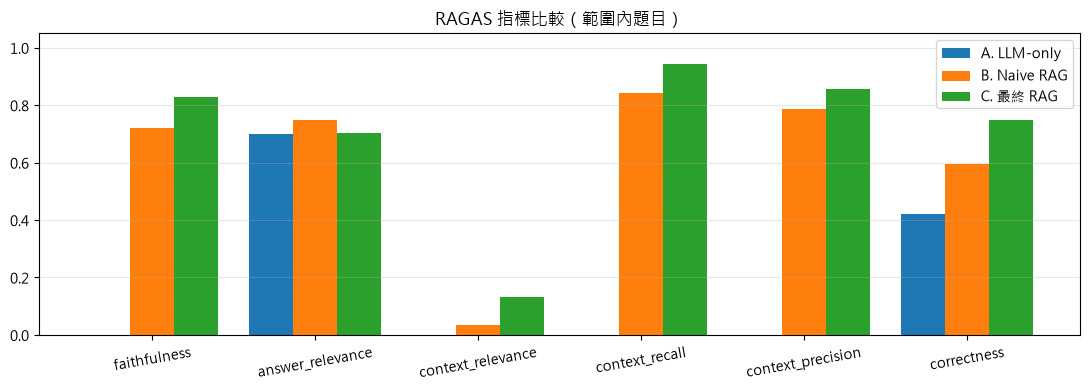

,faithfulness,answer_relevance,context_recall,correctness
類別,,,,
去漬,0.952,0.800,1.000,0.909
多輪,0.744,0.652,0.865,0.604
晾曬收納,0.875,0.708,1.000,0.875
材質保養,0.869,0.788,1.000,0.837
洗標符號,0.845,0.619,1.000,0.786
洗標辨識系統,0.875,0.752,1.000,0.812
洗滌技巧,0.880,0.807,1.000,0.950
疑難排解,0.938,0.826,1.000,0.938


In [29]:
ov = hw3[hw3.子集 == "整體（範圍內）"].set_index("系統")[cols]
fig, ax = plt.subplots(figsize=(11, 4)); x = np.arange(len(cols)); w = .27
for j, (n, r) in enumerate(ov.iterrows()): ax.bar(x + (j - 1) * w, r.fillna(0).values, w, label=n.split("（")[0])
ax.set_xticks(x); ax.set_xticklabels(cols, rotation=10); ax.set_ylim(0, 1.05); ax.legend(); ax.grid(axis="y", alpha=.3); ax.set_title("RAGAS 指標比較（範圍內題目）")
plt.tight_layout(); plt.savefig(OUT / "hw3_ragas_compare.png", dpi=130); plt.show()
# 依類別（單輪）
cat_of = {x["qid"]: x["category"] for x in ST}
items, meta, ev = EVAL["C. 最終 RAG（1.7 設定）"]
cat_df = ev.assign(類別=[cat_of.get(m["id"], "多輪") for m in meta], set=[m["set"] for m in meta])
display(cat_df[cat_df.set != "範圍外"].groupby("類別")[["faithfulness", "answer_relevance", "context_recall", "correctness"]].mean().round(3))

## 3.4 失敗案例檢視（最終系統 Correctness 最低的回答）

In [30]:
items, meta, ev = EVAL["C. 最終 RAG（1.7 設定）"]
bad = ev.assign(id=[m["id"] for m in meta], q=[it["question"] for it in items], query=[m["out"]["query"] for m in meta],
                a=[it["answer"] for it in items], gold=[",".join(it["gold"]) for it in items],
                got=[",".join(sorted(set().union(*[p["facts"] for p in it["passages"]]))) if it["passages"] else "" for it in items])
display(bad.sort_values(["correctness", "faithfulness"]).head(8)[["id", "q", "query", "a", "gold", "got", "correctness", "faithfulness", "context_recall"]])

,id,q,query,a,gold,got,correctness,faithfulness,context_recall
105,M11-2,那下面又多一條線呢？,那圓圈裡面的一個 F 下面又多了一條線呢？,圓圈裡面的一個 F 下面又多了一條線，表示該衣物只能使用碳氫類（石油系）溶劑進行專業乾洗，且處理過程需更加溫和。（依據 [1][3][7]）,PR05,"DR02,DR03,DR05,DR10,DR11,PR01,PR02,PR03,PR04,PR05,PR06,PR07",0.0,0.00,1.0
13,S14,熨斗一個點可以用蒸氣嗎？,熨斗一個點可以用蒸氣嗎？,熨斗內 1 個點表示低溫熨燙，底板最高約 110°C，且蒸氣可能造成損傷，因此不可使用蒸氣熨燙。（依據 [1]）,IR02,"IR01,IR02,IR03,IR04,IR05,IR06,IR07,IR08,SX07",0.0,0.75,1.0
14,S15,圓圈裡面一個 P 是什麼？,圓圈裡面一個 P 是什麼？,圓圈裡面一個 P 表示可專業乾洗，可使用四氯乙烯（PCE）以及碳氫類溶劑。（依據 [1]）,PR02,"DR01,DR02,PR01,PR02,PR03,PR04,PR05,PR06,PR07",0.0,1.00,1.0
93,M07-2,那一個點呢？,那三個點在熨斗符號裡面代表什麼呢？,熨斗符號裡面三個點表示高溫熨燙，底板最高約 200°C，適用於棉與麻。（依據 [1]）,IR02,"IR01,IR02,IR03,IR04,IR05,IR06,IR07,IR08,OV05",0.0,1.00,1.0
71,O02,幫我推薦台北好吃的牛肉麵,幫我推薦台北好吃的牛肉麵,抱歉，知識庫中沒有相關資訊。我只能回答衣物洗護與洗標相關的問題。,,,0.0,NaN,NaN
73,O04,Python 的 list 和 tuple 差在哪？,Python 的 list 和 tuple 差在哪？,抱歉，知識庫中沒有相關資訊。我只能回答衣物洗護與洗標相關的問題。,,,0.0,NaN,NaN
99,M09-2,它是亮亮的緞面材質一直反光,那件亮亮的緞面材質一直反光是他的衣物嗎？,抱歉，知識庫中沒有相關資訊。我只能回答衣物洗護與洗標相關的問題。,LP02,,0.0,NaN,0.0
106,M11-3,我拿去送洗要跟老闆說什麼？,那上面的線是什麼汙漬？,抱歉，知識庫中沒有相關資訊。我只能回答衣物洗護與洗標相關的問題。,PR09,,0.0,NaN,0.0


## 3.5 進階：VideoRAG 評估方法設計與實作

把 RAGAS 延伸到「影格 + 語音」兩種 context，並加入影片特有的時間定位與模態歸因：

| 面向 | 指標 | 計算方式 | 需要的標註 |
|---|---|---|---|
| 影片檢索 | Video Recall@1 / MRR | 檢索到的影片是否為正解影片 | `gold_video` |
| 時間定位 | Frame Hit Rate、Segment Recall | 選用影格落在正解時段（±2 秒）的比例；是否至少 1 張命中 | `gold_segments` |
| 影格選擇品質 | Visual Context Relevance | 選用影格與查詢的 CLIP 相似度，Adaptive vs Uniform | 無 |
| 忠實度（文字） | Transcript Faithfulness | 回答陳述能否由 ASR／畫面描述支持（同 RAGAS，Judge 為 Qwen2.5-3B） | 無 |
| 忠實度（視覺） | Visual Faithfulness | 由 Qwen2-VL 看選用影格，逐條回答「是／否」 | 無 |
| 忠實度（整體） | Multimodal Faithfulness | 陳述被「文字或影格」任一支持的比例 | 無 |
| 答案 | Answer Relevance、Correctness | 同 RAGAS；與人工撰寫的標準答案比較 | `answer` |
| 模態歸因 | V / T / VT 消融 | 只給影格、只給文字、兩者都給的 Correctness 差異（呼應論文 Table 4） | `answer` |
| 效率 | 影格數、延遲、顯存 | 計時 | 無 |

有聲影片預期 T 貢獻大；無聲操作影片只能靠 V（與畫面描述），可用 `needs` 欄位（visual / speech / both）分組觀察。評估集：`data/videos/video_benchmark.jsonl`（10 題、4 段對話，正解時段依 1 fps 影格人工標註）。

In [31]:
def frame_hit(frames_t, segs, tol=2.0):
    if not segs: return np.nan, np.nan
    hits = [any(s - tol <= t <= e + tol for s, e in segs) for t in frames_t]
    return float(np.mean(hits)), float(any(hits))

def vlm_yes(images, statement):
    content = [{"type": "image"} for _ in images] + [{"type": "text", "text": f"請只看上面的影片畫面，判斷下面這個陳述能否由畫面看出：「{statement}」\n只回答「是」或「否」。"}]
    return int("是" in vlm_chat([vtext("system", "你是嚴謹的影片內容評估員。"), {"role": "user", "content": content}], images=images, max_new_tokens=4)[:3])

def eval_videorag(bench, variants):
    """三階段：(1) VLM 生成所有回答；(2) Qwen2.5-3B 文字面評估（陳述拆解、逐字稿忠實度、正確性，同作業三）；(3) VLM 看影格做視覺忠實度。"""
    gens = []
    for vname, kw in variants.items():
        bot = VideoRAGBot(VINDEX, **kw)
        for dlg_id, grp in itertools.groupby(bench, key=lambda x: x.get("dialog_id", x["qid"])):
            bot.reset()
            for x in grp:
                o = bot.chat(x["question"])
                fhr, segr = frame_hit(o["frames"], x.get("gold_segments", []))
                vis_rel = float((clip_images(o["frame_images"]) @ clip_text([o["query_en"]])[0]).mean())
                gens.append(dict(variant=vname, x=x, o=o, frame_hit_rate=fhr, segment_recall=segr, visual_ctx_rel=vis_rel))
    L = get_llm()   # 釋放 VLM、載入文字 LLM
    st = L.chat([p_statements(g["o"]["query"], g["o"]["answer"]) for g in gens], max_new_tokens=300, desc="v-stmt")
    stmts = [[t for t in (parse_json(o, []) or []) if isinstance(t, str) and t.strip()][:10] for o in st]
    ctxs = ["\n".join(f"({mmss(s['start'])}) {s['text']}" for s in g["o"]["segments"]) or "（無）" for g in gens]
    idx = [i for i, s_ in enumerate(stmts) if s_]
    ve = dict(zip(idx, L.chat([p_verify(ctxs[i], stmts[i]) for i in idx], max_new_tokens=300, desc="v-verify")))
    co = L.chat([p_correct(g["x"]["question"], g["o"]["answer"], g["x"]["answer"]) for g in gens], max_new_tokens=100, desc="v-correct")
    vis = [[vlm_yes(g["o"]["frame_images"], t) for t in s_] for g, s_ in zip(gens, stmts)]   # 重新載入 VLM
    rows = []
    for i, g in enumerate(gens):
        x, o = g["x"], g["o"]
        v = parse_json(ve.get(i, "[]"), []) or []
        d = {int(e.get("id", j + 1)): int(bool(e.get("verdict", 0))) for j, e in enumerate(v) if isinstance(e, dict)}
        t_ok = [d.get(j + 1, 0) for j in range(len(stmts[i]))]
        js = parse_json(co[i], {}) or {}; sc = js.get("score") if isinstance(js, dict) else None
        rows.append(dict(variant=g["variant"], qid=x["qid"], needs=x.get("needs", ""), video_hit=float(o["video_id"] == x["gold_video"]),
                         frame_hit_rate=g["frame_hit_rate"], segment_recall=g["segment_recall"], visual_ctx_rel=g["visual_ctx_rel"],
                         text_faith=np.mean(t_ok) if t_ok else np.nan, visual_faith=np.mean(vis[i]) if vis[i] else np.nan,
                         mm_faith=np.mean([a or b for a, b in zip(t_ok, vis[i])]) if t_ok else np.nan,
                         correctness=(min(5, max(1, int(sc))) - 1) / 4 if isinstance(sc, (int, float)) else np.nan,
                         latency=o["latency"], n_frames=len(o["frames"]), answer=o["answer"]))
    return pd.DataFrame(rows)

VBENCH = VIDEO_DIR / "video_benchmark.jsonl"
if HAS_VIDEO and VBENCH.exists():
    vb = read_jsonl(VBENCH)
    variants = {"VT-Adaptive（本系統）": dict(), "VT-Uniform": dict(selection="uniform"),
                "V-only（不給文字）": dict(use_text=False), "T-only 檢索（α=1）": dict(modality="t")}
    vres = eval_videorag(vb, variants); vres.to_csv(OUT / "hw3_videorag_eval.csv", index=False)
    display(vres.groupby("variant").mean(numeric_only=True).round(4))
    display(vres.groupby(["variant", "needs"])[["correctness", "text_faith", "visual_faith"]].mean().round(4))
else:
    print("尚無影片或 video_benchmark.jsonl：VideoRAG 評估只定義流程、不執行。")


Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]


Loading weights:   5%|▍         | 34/729 [00:00<00:02, 305.89it/s]


Loading weights:   9%|▉         | 65/729 [00:00<00:02, 265.94it/s]


Loading weights:  13%|█▎        | 92/729 [00:00<00:02, 245.84it/s]


Loading weights:  16%|█▌        | 117/729 [00:00<00:02, 230.61it/s]


Loading weights:  19%|█▉        | 141/729 [00:00<00:02, 219.04it/s]

... (65 outputs left out)


Loading weights:  94%|█████████▍| 688/729 [00:02<00:00, 437.75it/s]


Loading weights: 100%|██████████| 729/729 [00:02<00:00, 291.04it/s]

,video_hit,frame_hit_rate,segment_recall,visual_ctx_rel,text_faith,visual_faith,mm_faith,correctness,latency,n_frames
variant,,,,,,,,,,
T-only 檢索（α=1）,1.0,0.4875,1.0,0.2666,0.4583,0.7333,0.900,0.3056,2.1541,8.0
V-only（不給文字）,1.0,0.5125,1.0,0.2621,0.1400,0.9050,0.905,0.2750,2.2980,8.0
VT-Adaptive（本系統）,1.0,0.4875,1.0,0.2666,0.4583,0.7333,0.900,0.3056,2.6342,8.0
VT-Uniform,1.0,0.5125,1.0,0.2596,0.3250,0.8500,0.850,0.3750,2.4191,8.0


correctness  text_faith  visual_faith
variant          needs                                        
T-only 檢索（α=1）   both         0.0833      0.7222        0.6667
                 speech          NaN      1.0000        0.5000
                 visual       0.4167      0.2361        0.8056
V-only（不給文字）     both         0.3333      0.3333        0.9167
                 speech       0.0000      0.0000        1.0000
                 visual       0.2917      0.0667        0.8833
VT-Adaptive（本系統） both         0.0833      0.7222        0.6667
                 speech          NaN      1.0000        0.5000
                 visual       0.4167      0.2361        0.8056
VT-Uniform       both         0.4167      0.5000        0.8333
                 speech       0.0000      0.5000        0.5000
                 visual       0.4167      0.2083        0.9167

---
# 作業四：GraphRAG（VideoRAG 論文）

**論文：** Jeong et al., *VideoRAG: Retrieval-Augmented Generation over Video Corpus*（ACL Findings 2025；arXiv 2501.05874v3，存於 `data/paper/videorag.pdf`）。

**流程（參考 Microsoft GraphRAG）：**
1. 論文全文切塊 → LLM 抽取實體（方法、模型、資料集、指標、結果…）與關係 → 實體正規化與合併 → 知識圖譜。
2. Louvain 社群偵測 → LLM 為每個社群寫摘要報告。
3. 查詢：**Local Search**（查詢 ↔ 實體向量 → 1-hop 鄰居關係 + 實體連結的原文片段）、**Global Search**（對所有社群報告 map-reduce）、**Hybrid**（最相關社群報告 + 實體／關係 + 向量檢索的原文 chunk）。
4. 以 24 題自製 Benchmark（15 題細節、5 題多跳推理、4 題全域摘要／5W1H）與 No-RAG、Naive RAG 比較。

## 4.1 論文文字與切塊

In [32]:
import pymupdf
PAPER = DATA / "paper" / "videorag.pdf"
raw = "\n".join(p.get_text() for p in pymupdf.open(PAPER))
i_ref, i_app = raw.find("\nReferences\n"), raw.find("Additional Implementation Details")
paper_text = raw[:i_ref] + "\n" + raw[i_app:] if 0 < i_ref < i_app else raw
i_ack = paper_text.find("Acknowledg")
if 0 < i_ack < i_ref: paper_text = paper_text[:i_ack] + "\n" + paper_text[paper_text.find("Additional Implementation Details"):]
paper_text = re.sub(r"-\n(\w)", r"\1", paper_text)
paper_text = re.sub(r"\s*\n\s*", " ", paper_text)
paper_text = re.sub(r"\((?:[^()]*?(?:et al\.|\b(?:19|20)\d{2}\b)[^()]*?)\)", "", paper_text)   # 去除行內引用，如 (Lewis et al., 2020)
paper_text = re.sub(r"\s{2,}", " ", paper_text).strip()

def sent_chunks(text, size=1200, overlap=200):
    sents = re.split(r"(?<=[.!?])\s+", text); chunks, cur = [], ""
    for s in sents:
        if len(cur) + len(s) > size and cur:
            chunks.append(cur.strip()); cur = cur[-overlap:]
        cur += " " + s
    if cur.strip(): chunks.append(cur.strip())
    return chunks
P_CHUNKS = sent_chunks(paper_text)
P_CE = emb.encode(P_CHUNKS)
PQA = read_jsonl(DATA / "benchmark" / "paper_qa.jsonl")
print(f"論文 {len(raw):,} 字元 → 去除參考文獻後 {len(paper_text):,} 字元 → {len(P_CHUNKS)} chunks；Benchmark {len(PQA)} 題 {Counter(q['type'] for q in PQA)}")

論文 89,100 字元 → 去除參考文獻後 59,768 字元 → 67 chunks；Benchmark 24 題 Counter({'local': 15, 'multi_hop': 5, 'global': 4})


## 4.2 LLM 抽取實體與關係

In [33]:
EX_SYS = "You are an information extraction system that builds a knowledge graph from a research paper. Output JSON only."
ETYPES = ["METHOD", "MODEL", "DATASET", "METRIC", "TASK", "CONCEPT", "RESULT", "ORGANIZATION", "PERSON"]
def ex_prompt(chunk):
    return msgs(EX_SYS, f"""Extract the important entities and relations from the text below (a part of the VideoRAG paper).
Entity types: {", ".join(ETYPES)}.
Rules:
- Use short canonical names, e.g. "VideoRAG", "InternVideo2", "ROUGE-L", "k-means++ clustering", "WikiHowQA".
- description: one sentence faithful to the text; keep numbers (scores, frame counts, ratios) when present.
- Each relation links two extracted entities with a short verb phrase, plus a one-sentence description.
- Do NOT extract cited authors or citation markers (e.g. "Lewis et al."); use PERSON/ORGANIZATION only for this paper's own authors and affiliations.
- Extract at most 15 entities and 15 relations.
Return: {{"entities": [{{"name": "...", "type": "...", "description": "..."}}], "relations": [{{"source": "...", "target": "...", "relation": "...", "description": "..."}}]}}

Text:
{chunk}""")

def salvage(text):
    """JSON 被截斷時，逐一取出完整的 {...} 物件。"""
    ents, rels = [], []
    for m in re.finditer(r"\{[^{}]*\}", text):
        try: o = json.loads(m.group())
        except json.JSONDecodeError: continue
        if "name" in o: ents.append(o)
        elif "source" in o and "target" in o: rels.append(o)
    return dict(entities=ents, relations=rels)

ex_out = get_llm().chat([ex_prompt(c) for c in P_CHUNKS], max_new_tokens=1100, bs=8, desc="extract")
EXTRACT = []
for ci, o in enumerate(ex_out):
    js = parse_json(o, None)
    if not (isinstance(js, dict) and "entities" in js): js = salvage(o)
    EXTRACT.append(dict(chunk=ci, entities=[e for e in js.get("entities", []) if isinstance(e, dict) and e.get("name")],
                        relations=[r for r in js.get("relations", []) if isinstance(r, dict) and r.get("source") and r.get("target")]))
write_jsonl(OUT / f"{sfx('hw4_extraction')}.jsonl", EXTRACT)
print(f"原始抽取：{sum(len(e['entities']) for e in EXTRACT)} 個實體、{sum(len(e['relations']) for e in EXTRACT)} 條關係")


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]


Loading weights:   1%|          | 5/434 [00:00<00:09, 45.61it/s]


Loading weights:   4%|▎         | 16/434 [00:00<00:05, 81.27it/s]


Loading weights:   6%|▌         | 27/434 [00:00<00:04, 89.19it/s]


Loading weights:   9%|▉         | 40/434 [00:00<00:03, 98.74it/s]


Loading weights:  12%|█▏        | 53/434 [00:00<00:03, 109.15it/s]

... (25 outputs left out)


Loading weights:  94%|█████████▎| 406/434 [00:03<00:00, 105.04it/s]


Loading weights:  98%|█████████▊| 425/434 [00:03<00:00, 123.23it/s]


Loading weights: 100%|██████████| 434/434 [00:03<00:00, 111.95it/s]

原始抽取：518 個實體、320 條關係


## 4.3 實體正規化、合併與建圖

In [34]:
import networkx as nx
def norm_name(n):
    n = str(n).strip().strip("\"'").lower()
    n = re.sub(r"[\s_]+", " ", n); n = re.sub(r"[^\w\s+.#\-]", "", n).strip()
    n = re.sub(r"\s*-\s*", "-", n)
    if len(n) > 4 and n.endswith("s") and not n.endswith(("ss", "us", "is")): n = n[:-1]
    return n

surface = defaultdict(Counter)
for ex in EXTRACT:
    for e in ex["entities"]: surface[norm_name(e["name"])][str(e["name"]).strip()] += 1
    for r in ex["relations"]:
        for k in ("source", "target"): surface[norm_name(r[k])][str(r[k]).strip()] += 1
keys = [k for k in surface if k]
KE = emb.encode(keys)
parent = {k: k for k in keys}
def find(x):
    while parent[x] != x: parent[x] = parent[parent[x]]; x = parent[x]
    return x
S = KE @ KE.T
for i in range(len(keys)):
    for j in range(i + 1, len(keys)):
        if S[i, j] > 0.93: parent[find(keys[j])] = find(keys[i])
canon = {}
for k in keys:
    root = find(k); canon[k] = root
group_names = defaultdict(Counter)
for k in keys: group_names[canon[k]].update(surface[k])
display_name = {g: c.most_common(1)[0][0] for g, c in group_names.items()}
def cid(name): return display_name[canon[norm_name(name)]]

G = nx.Graph()
for ex in EXTRACT:
    for e in ex["entities"]:
        n = cid(e["name"]); t = str(e.get("type", "CONCEPT")).upper(); t = t if t in ETYPES else "CONCEPT"
        if n not in G: G.add_node(n, types=Counter(), desc=[], chunks=set())
        G.nodes[n]["types"][t] += 1; G.nodes[n]["chunks"].add(ex["chunk"])
        if e.get("description"): G.nodes[n]["desc"].append(str(e["description"]))
    for r in ex["relations"]:
        a, b = cid(r["source"]), cid(r["target"])
        if a == b: continue
        for n in (a, b):
            if n not in G: G.add_node(n, types=Counter({"CONCEPT": 1}), desc=[], chunks=set())
            G.nodes[n]["chunks"].add(ex["chunk"])
        if not G.has_edge(a, b): G.add_edge(a, b, rels=[], weight=0, chunks=set())
        G[a][b]["rels"].append(f"{r.get('relation', 'related to')}: {r.get('description', '')}".strip()); G[a][b]["weight"] += 1; G[a][b]["chunks"].add(ex["chunk"])
for n in G.nodes:
    d = G.nodes[n]; d["type"] = d["types"].most_common(1)[0][0]
    d["description"] = " ".join(dict.fromkeys(d["desc"]))[:600] or n
G.remove_nodes_from([n for n in list(G.nodes) if G.degree(n) == 0 and len(G.nodes[n]["desc"]) == 0])
print(f"合併後：{G.number_of_nodes()} 個節點、{G.number_of_edges()} 條邊（合併 {len(keys) - len(set(canon.values()))} 組同義名稱）")
display(pd.DataFrame(sorted(((n, G.nodes[n]["type"], G.degree(n)) for n in G.nodes), key=lambda x: -x[2])[:15], columns=["實體", "類型", "度數"]))
display(pd.Series([G.nodes[n]["type"] for n in G.nodes]).value_counts().to_frame("節點數").T)

合併後：244 個節點、194 條邊（合併 2 組同義名稱）


,實體,類型,度數
0,VideoRAG,METHOD,75
1,LVLMs,MODEL,19
2,k-means++ clustering,CONCEPT,10
3,VIDEORAG-V,METHOD,10
4,TEXTVIDEORAG,MODEL,9
5,VideoRAG-VT,MODEL,8
6,Making Clay Rose,TASK,8
7,videos,DATASET,6
8,WikiHowQA,DATASET,6
9,InternVL 2.5,MODEL,5


,CONCEPT,RESULT,MODEL,METHOD,TASK,DATASET,METRIC,PERSON,ORGANIZATION
節點數,91,33,28,24,23,17,11,10,7


## 4.4 社群偵測與社群報告

In [35]:
# 排序鍵全部明確指定（度數相同再依名稱），避免集合順序隨 PYTHONHASHSEED 改變 → prompt 改變、結果與快取不可重現
COMMS = [sorted(c, key=lambda n: (-G.degree(n), n)) for c in nx.community.louvain_communities(G, weight="weight", seed=SEED, resolution=1.6)]
COMMS = sorted([c for c in COMMS if len(c) >= 2], key=lambda c: (-len(c), c[0]))
for ci, c in enumerate(COMMS):
    for n in c: G.nodes[n]["community"] = ci
def comm_prompt(c):
    ents = "\n".join(f"- {n} ({G.nodes[n]['type']}): {G.nodes[n]['description'][:250]}" for n in c[:25])
    rels = []
    for a, b in sorted(tuple(sorted(e)) for e in G.subgraph(c).edges()):   # subgraph 的邊順序依集合而定，需排序
        rels.append(f"- {a} -- {b}: {G[a][b]['rels'][0][:200]}")
    rels = "\n".join(rels[:30]) or "(none)"
    return msgs("You write concise community reports for a knowledge graph built from the VideoRAG paper. Output JSON only.",
                f"""Write a report for this community of entities.
Return {{"title": "short title", "summary": "4-6 sentences explaining what these entities are, how they relate, and key numbers/findings from the paper"}}

Entities:
{ents}

Relations:
{rels}""")
rep_out = get_llm().chat([comm_prompt(c) for c in COMMS], max_new_tokens=400, bs=8, desc="community reports")
REPORTS = []
for ci, (c, o) in enumerate(zip(COMMS, rep_out)):
    js = parse_json(o, {}) or {}
    title = js.get("title", c[0]) if isinstance(js, dict) else c[0]
    summ = js.get("summary", o) if isinstance(js, dict) else o
    REPORTS.append(dict(cid=ci, title=str(title), summary=str(summ), size=len(c), entities=c[:12]))
R_E = emb.encode([f"{r['title']}. {r['summary']}" for r in REPORTS])
write_jsonl(OUT / f"{sfx('hw4_community_reports')}.jsonl", REPORTS)
display(pd.DataFrame(REPORTS)[["cid", "size", "title", "entities"]])

,cid,size,title,entities
0,0,55,VideoRAG Framework and Evaluation,"[VideoRAG, k-means++ clustering, WikiHowQA, InternVideo2, HowTo100M, frame selection, 32, 40, 64, 64C32, 8 candidate..."
1,1,16,Multimodal Processing and Analysis by Large Video Language Models,"[LVLMs, frames, Ftext, TextEncoder, VisionEncoder, zero-shot settings, Fvisual, action detection, bias, causal relat..."
2,2,14,Video Retrieval and Generation Models,"[VIDEORAG-V, TEXTVIDEORAG, VideoRAG-VT, TextImageRAG, NAÏVE baseline, TextRAG(BM25), Human Evaluation, TEXTRAG, Acor..."
3,3,11,Video Retrieval and Augmentation with RAG,"[Retriever, ˜V, CLIP, f, fvideo, q, Comb(·), Wikipedia, fquery, 4 frames, C]"
4,4,9,Clay Rose Creation Process,"[Making Clay Rose, Adding leaves, Assembling petals, Creating indentations, Cutting petal shapes, Flattening clay, R..."
5,5,5,Rose Making Tools and Materials,"[petals, clay, glue, sponge, tool]"
6,6,5,Community of Useful Video Content,"[useful video content, educational tutorials, personal experiences, real-time events, scientific demonstrations]"
7,7,5,Exploring Videos as Multimodal Richness,"[videos, multimodal cues, spatial details, static modalities, temporal dynamics]"
8,8,4,Retrieval-Augmented Generation in Text and Images,"[RAG, image, Multimodal RAG, text]"
9,9,4,Video Retrieval Methods Comparison,"[Video Set, Oracle, Random, Retrieved]"


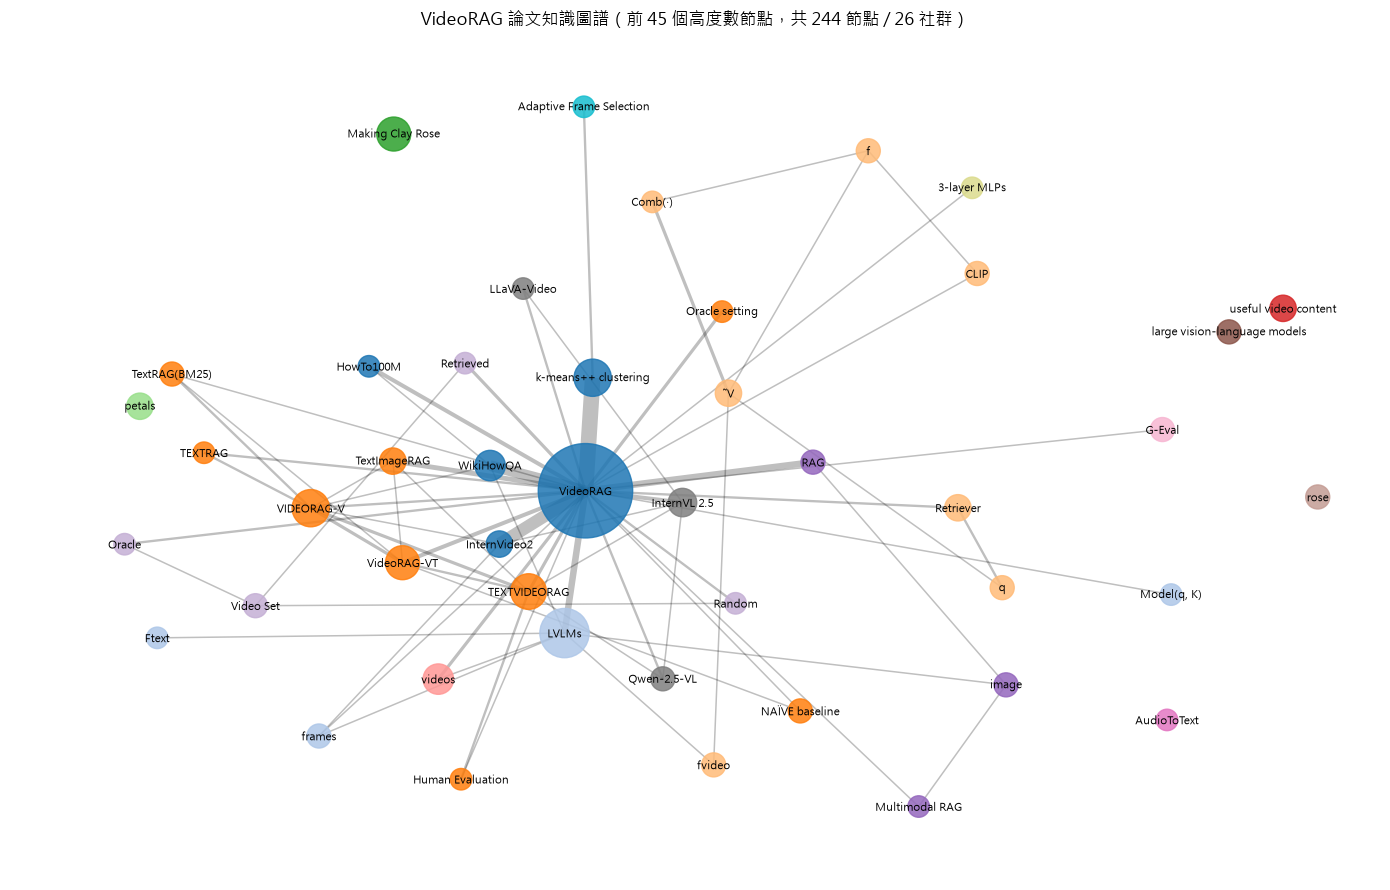

In [36]:
# 視覺化：度數最高的 45 個節點，依社群著色
top_nodes = sorted(G.nodes, key=lambda n: (-G.degree(n), n))[:45]
H = G.subgraph(top_nodes)
pos = nx.spring_layout(H, seed=SEED, k=0.9, weight="weight")
cmap = plt.get_cmap("tab20")
fig, ax = plt.subplots(figsize=(14, 9))
nx.draw_networkx_edges(H, pos, alpha=.25, width=[0.5 + H[a][b]["weight"] * .6 for a, b in H.edges()], ax=ax)
nx.draw_networkx_nodes(H, pos, node_size=[120 + 60 * G.degree(n) for n in H.nodes], node_color=[cmap(G.nodes[n].get("community", 0) % 20) for n in H.nodes], alpha=.85, ax=ax)
nx.draw_networkx_labels(H, pos, font_size=8, ax=ax)
ax.set_title(f"VideoRAG 論文知識圖譜（前 45 個高度數節點，共 {G.number_of_nodes()} 節點 / {len(COMMS)} 社群）"); ax.axis("off")
plt.tight_layout(); plt.savefig(OUT / "hw4_graph.png", dpi=130); plt.show()
graph_json = dict(nodes=[dict(id=n, type=G.nodes[n]["type"], community=G.nodes[n].get("community"), description=G.nodes[n]["description"],
                               chunks=sorted(G.nodes[n]["chunks"])) for n in G.nodes],
                  edges=[dict(source=a, target=b, weight=G[a][b]["weight"], relations=G[a][b]["rels"], chunks=sorted(G[a][b]["chunks"])) for a, b in G.edges])
json.dump(graph_json, open(OUT / f"{sfx('hw4_graph')}.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)

## 4.5 Local / Global / Hybrid 查詢與基準方法

In [37]:
NODES = list(G.nodes)
N_E = emb.encode([f"{n} ({G.nodes[n]['type']}): {G.nodes[n]['description'][:300]}" for n in NODES])
ANS_SYS = "你是 AI 論文問答助理。只根據提供的論文資料，用繁體中文回答；資料中沒有的內容請說「資料中沒有提到」。回答要完整列出關鍵要點與數字，3~6 句。"

def local_context(q, k_ent=8, max_rel=24, k_chunks=3):
    qv = emb.encode([q])[0]; s = N_E @ qv
    ents = [NODES[i] for i in np.argsort(-s)[:k_ent]]
    rels = []
    for n in ents:
        for nb in G.neighbors(n):
            rels.append((G[n][nb]["weight"] + float(N_E[NODES.index(nb)] @ qv), n, nb))
    rels = sorted(set(rels), key=lambda x: (-x[0], x[1], x[2]))[:max_rel]   # 同分時依名稱，結果可重現
    chunk_ids = Counter(c for n in ents for c in G.nodes[n]["chunks"])
    cands = list(chunk_ids)
    if cands and k_chunks > 0:
        cs = P_CE[cands] @ qv; cands = [cands[i] for i in np.argsort(-(cs + 0.02 * np.array([chunk_ids[c] for c in cands])))[:k_chunks]]
    txt = "## 實體\n" + "\n".join(f"- {n} ({G.nodes[n]['type']}): {G.nodes[n]['description'][:300]}" for n in ents)
    txt += "\n## 關係\n" + "\n".join(f"- {a} — {b}: {G[a][b]['rels'][0][:200]}" for _, a, b in rels)
    cands = cands if k_chunks > 0 else []
    if cands: txt += "\n## 原文片段\n" + "\n".join(f"[chunk {c}] {P_CHUNKS[c]}" for c in cands)
    return txt, ents, cands

def answer_with(q, ctx, mnt=400):
    return msgs(ANS_SYS, f"論文資料：\n{ctx}\n\n問題：{q}\n回答：")

def run_norag(qs): return get_llm().chat([msgs("你是 AI 論文問答助理，用繁體中文回答，3~6 句。", f"關於 VideoRAG（Retrieval-Augmented Generation over Video Corpus）這篇論文：{q}") for q in qs], max_new_tokens=400, desc="No-RAG")
def run_naive(qs, k=4):
    ctxs = []
    for q in qs:
        s = P_CE @ emb.encode([q])[0]; ctxs.append("\n\n".join(f"[chunk {i}] {P_CHUNKS[i]}" for i in np.argsort(-s)[:k]))
    return get_llm().chat([answer_with(q, c) for q, c in zip(qs, ctxs)], max_new_tokens=400, desc="Naive RAG"), ctxs
def run_local(qs):
    ctxs = [local_context(q)[0] for q in qs]
    return get_llm().chat([answer_with(q, c) for q, c in zip(qs, ctxs)], max_new_tokens=400, desc="Local"), ctxs
def map_prompt(q, r):
    return msgs("你是論文問答助理。只輸出 JSON。", f"""根據下面這份知識圖譜社群報告，回答問題中與本報告相關的部分。
輸出 JSON：{{"score": 0~100 的整數（這份報告對回答問題的幫助程度，無關則 0）, "points": ["繁體中文要點", ...]}}
社群報告：{r['title']}：{r['summary']}
問題：{q}""")
def run_global(qs, top=6):
    jobs = [(qi, ri) for qi in range(len(qs)) for ri in range(len(REPORTS))]
    outs = get_llm().chat([map_prompt(qs[qi], REPORTS[ri]) for qi, ri in jobs], max_new_tokens=220, desc="Global-map")
    partial = defaultdict(list)
    for (qi, ri), o in zip(jobs, outs):
        js = parse_json(o, {}) or {}
        sc = js.get("score", 0) if isinstance(js, dict) else 0
        pts = [p for p in (js.get("points", []) if isinstance(js, dict) else []) if isinstance(p, str)]
        if isinstance(sc, (int, float)) and sc > 0 and pts: partial[qi].append((sc, ri, pts))
    ctxs = []
    for qi in range(len(qs)):
        ps = sorted(partial[qi], key=lambda x: -x[0])[:top]
        ctxs.append("\n".join(f"- （社群 {ri}，相關度 {sc}）" + "；".join(pts) for sc, ri, pts in ps) or "（無相關社群）")
    return get_llm().chat([answer_with(q, "以下是知識圖譜各社群整理出的要點：\n" + c) for q, c in zip(qs, ctxs)], max_new_tokens=400, desc="Global-reduce"), ctxs
def run_hybrid(qs, top_r=3, k_chunks=4):
    """Graph（社群報告 + 實體/關係）+ Vector（直接檢索的原文 chunk）。"""
    ctxs = []
    for q in qs:
        qv = emb.encode([q])[0]
        lc, ents, used = local_context(q, k_chunks=0)
        rs = R_E @ qv
        rep = "\n".join(f"- {REPORTS[i]['title']}：{REPORTS[i]['summary']}" for i in np.argsort(-rs)[:top_r])
        cs = [int(i) for i in np.argsort(-(P_CE @ qv))[:k_chunks]]
        ctxs.append(f"## 社群報告（全域脈絡）\n{rep}\n{lc}\n" + "\n".join(f"[chunk {c}] {P_CHUNKS[c]}" for c in cs))
    return get_llm().chat([answer_with(q, c) for q, c in zip(qs, ctxs)], max_new_tokens=450, desc="Hybrid"), ctxs

print(local_context("VideoRAG 用什麼方法縮小 frame selection 的搜尋空間？")[0][:1500])

## 實體
- frame reduction (CONCEPT): Reducing the number of frames in a video
- VideoRAG (METHOD): a novel framework for retrieval-augmented generation over video corpus a novel framework for dynamically retrieving videos based on their relevance with queries a large foundation model for video-text retrieval proposed video-retrieval and generation method an emerging approach for mitigating factua
- VIDEORAG-V (METHOD): one variant of VideoRAG that uses video frames as context A model for video retrieval. A variant of VideoRAG retrieves the relevant video that illustrates the process of baking cookies on a car dashboard utilizes external video content to produce more precise, contextually rich, and actionable answe
- Figure 5 (RESULT): a figure showing the performance of VideoRAG with different InternVL2.5 sizes
- G (TASK): generating videos containing a large number of visual frames
- VIDEOR2https://www.wikihow.com/Main-Page AG-VT (MODEL): another variant of VideoRAG that jointly uses vi

## 4.6 Benchmark 評估

- **Correctness：** Judge 依標準答案給 1~5 分 → 0~1。
- **Key-Point Recall：** 每題 2~6 個關鍵要點，Judge 逐點判斷是否涵蓋。
- **Semantic Sim：** 回答與標準答案的 bge-m3 cosine。
- **Faithfulness：** 同作業三，檢查回答是否被該方法提供的 context 支持（No-RAG 無 context 不計）。

In [38]:
qs = [q["question"] for q in PQA]
PRED = {"No-RAG": (run_norag(qs), None)}
PRED["Naive RAG（chunk Top-4）"] = run_naive(qs)
PRED["GraphRAG-Local"] = run_local(qs)
PRED["GraphRAG-Global"] = run_global(qs)
PRED["GraphRAG-Hybrid"] = run_hybrid(qs)

def p_keypoints(q, a, kps):
    s = "\n".join(f"{i+1}. {k}" for i, k in enumerate(kps))
    return msgs(JUDGE_SYS, f"判斷「模型回答」是否涵蓋下列每個關鍵要點（意思相同即可，涵蓋=1，未涵蓋或錯誤=0）。輸出 JSON 整數陣列，長度與要點數相同。\n問題：{q}\n模型回答：{a}\n關鍵要點：\n{s}")
rows = []
for mname, (answers, ctxs) in PRED.items():
    co = get_llm().chat([p_correct(q["question"], a, q["answer"]) for q, a in zip(PQA, answers)], max_new_tokens=100, desc=f"judge-{mname[:6]}")
    kp = get_llm().chat([p_keypoints(q["question"], a, q["key_points"]) for q, a in zip(PQA, answers)], max_new_tokens=60, desc=f"kp-{mname[:6]}")
    sims = (emb.encode(answers) * emb.encode([q["answer"] for q in PQA])).sum(1)
    if ctxs is not None:
        fa = ragas_eval([dict(question=q["question"], answer=a, contexts=[c], gold=[], refused=False) for q, a, c in zip(PQA, answers, ctxs)], desc=f"faith-{mname[:6]}")["faithfulness"].values
    else:
        fa = [np.nan] * len(PQA)
    for q, a, c, k, s, f in zip(PQA, answers, co, kp, sims, fa):
        js = parse_json(c, {}) or {}; sc = js.get("score") if isinstance(js, dict) else None
        kv = [int(bool(x)) for x in (parse_json(k, []) or []) if isinstance(x, (int, float, bool))][:len(q["key_points"])]
        kv += [0] * (len(q["key_points"]) - len(kv))
        rows.append(dict(方法=mname, qid=q["qid"], type=q["type"], correctness=(min(5, max(1, int(sc))) - 1) / 4 if isinstance(sc, (int, float)) else np.nan,
                         keypoint_recall=np.mean(kv), semantic_sim=float(s), faithfulness=f, answer=a))
hw4 = pd.DataFrame(rows); hw4.to_csv(OUT / f"{sfx('hw4_benchmark_preds')}.csv", index=False)
mcols = ["correctness", "keypoint_recall", "semantic_sim", "faithfulness"]
hw4_tab = hw4.groupby("方法", sort=False)[mcols].mean()
hw4_type = hw4.pivot_table(index="方法", columns="type", values="keypoint_recall", sort=False)[["local", "multi_hop", "global"]]
hw4_tab.to_csv(OUT / f"{sfx('hw4_results')}.csv"); hw4_type.to_csv(OUT / f"{sfx('hw4_results_by_type')}.csv")
display(hw4_tab.round(4)); display(hw4_type.round(4).rename(columns=lambda c: f"KP-Recall｜{c}"))

,correctness,keypoint_recall,semantic_sim,faithfulness
方法,,,,
No-RAG,0.2812,0.0833,0.6137,NaN
Naive RAG（chunk Top-4）,0.5109,0.5035,0.7220,0.8725
GraphRAG-Local,0.4167,0.3854,0.6968,0.7785
GraphRAG-Global,0.2708,0.1458,0.6176,0.6899
GraphRAG-Hybrid,0.4375,0.4028,0.7077,0.8542


type,KP-Recall｜local,KP-Recall｜multi_hop,KP-Recall｜global
方法,,,
No-RAG,0.0389,0.2333,0.0625
Naive RAG（chunk Top-4）,0.5167,0.6500,0.2708
GraphRAG-Local,0.4222,0.4500,0.1667
GraphRAG-Global,0.1500,0.1667,0.1042
GraphRAG-Hybrid,0.4222,0.5167,0.1875


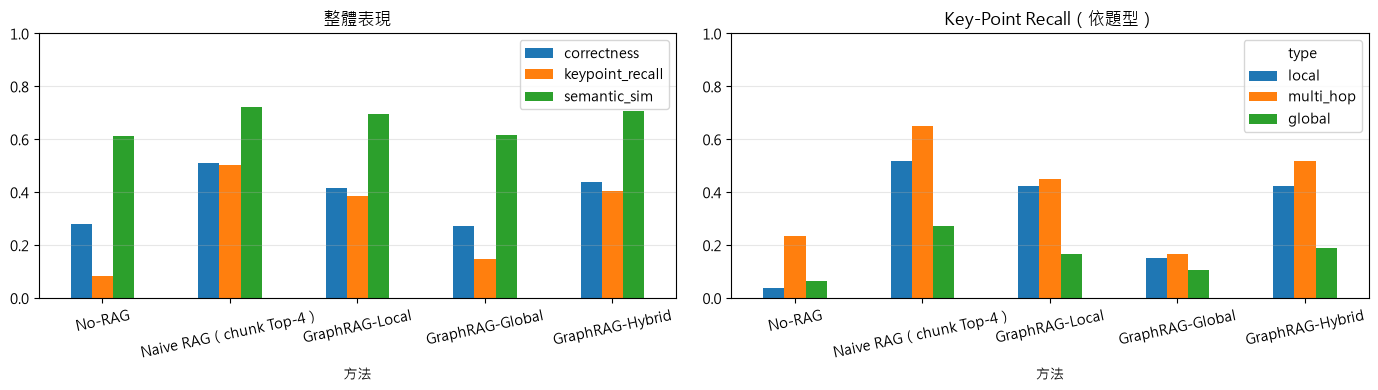

**P02｜VideoRAG 用什麼方法縮小 frame selection 的搜尋空間？**

,方法,correctness,keypoint_recall,answer
1,No-RAG,0.25,0.000000,VideoRAG 使用預訓練的視頻摘要模型來精確選取關鍵frame，以此縮小frame selection的搜尋空間。
25,Naive RAG（chunk Top-4）,0.75,0.666667,VideoRAG 使用 k-means++ 集群的方法來縮小 frame selection 的搜尋空間。具體來說，它會將所有 frame 分成 k 個群組，然後從每個群組中選擇最接近其中心點的 frame，以此作為代表樣本。
49,GraphRAG-Local,0.75,0.666667,VideoRAG 使用 k-means++ 集群的方法來縮小 frame selection 的搜尋空間。具體來說，它會將所有 frame 分成 k 群組，然後從每個群組中選擇最接近其中心的 frame。
73,GraphRAG-Global,0.25,0.000000,VideoRAG 使用多種方法來縮小 frame selection 的搜尋空間，包括 adaptive frame selection 方法（社群 18，相關度 80）、Clustering 方法（社群 19，相關度 80），以及...
97,GraphRAG-Hybrid,0.75,0.666667,VideoRAG 使用 k-means++ 集群的方法來縮小 frame selection 的搜尋空間。具體來說，它會將所有 frame 分成 k 組，然後從每組的中心點最近的 frame 中選取，以此作為代表樣本。


**P16｜為什麼同時加入 Wikipedia 文字文件和影片，表現反而下降？**

,方法,correctness,keypoint_recall,answer
15,No-RAG,0.75,0.333333,可能因為影片內容豐富且多樣，直接加入可能會過度複雜，影響模型的訓練效果，導致表現下降。
39,Naive RAG（chunk Top-4）,0.75,1.000000,同時加入 Wikipedia 文字文件和影片，表現反而下降的原因可能是，文字內容可能包含冗餘或不相關的細節，這些細節可能會與影片中的資訊重複或矛盾，導致 VideoRAG 框架的有效性降低。
63,GraphRAG-Local,0.25,0.333333,同時加入 Wikipedia 文字文件和影片的表現反而下降，可能因為該方法達成的效果稍為不如單純使用文字文件的表現，具體來說是「稍為降級」。
87,GraphRAG-Global,0.75,0.000000,同時加入Wikipedia的文字文件和影片，表現反而下降可能是因為模型需要處理更多的資訊來進行視覺和文本的整合，導致複雜度增加，影響了模型的效能。資料中沒有提到具體原因，但可能與影片數據較為複雜且非結構化，與文字數據之間的整合難度較...
111,GraphRAG-Hybrid,0.75,1.000000,同時加入 Wikipedia 文字文件和影片的表現反而下降，可能因為文字文件中的資訊可能包含冗餘或不相關細節，這些細節可能會與影片中的資訊重疊或矛盾，導致 VideoRAG 模型的有效性降低。


**P22｜請用 5W1H 整理這篇論文。**

,方法,correctness,keypoint_recall,answer
21,No-RAG,0.25,0.0,何時：VideoRAG 是在 2021 年提出的。\n何地：未特別指出是特定的地點。\n何事：提出了一種名為 VideoRAG 的方法，用於生成視頻內容。\n誰做：研究人員開發了這個模型。\n為什麼：為了提高視頻生成的質量和相關性，...
45,Naive RAG（chunk Top-4）,0.25,0.0,何（What）：本文比較了不同模型在視頻回應生成任務上的表現，並分析了視覺和文本特徵的組合對性能的影響。\n何時（When）：未提供具體時間。\n何地（Where）：未提供具體地點。\n誰（Who）：未指定作者或研究團隊。\n為什麼...
69,GraphRAG-Local,0.25,0.0,何（What）：VideoRAG 是一種新的框架，用於利用視頻中的視覺和文本信息來改善生成過程的準確性。\n在哪裡（Where）：本文發表在某期刊上，具體位置未提及。\n何時（When）：論文發表時間未提及。\n誰（Who）：Sun...
93,GraphRAG-Global,0.25,0.0,這篇論文可以使用 5W1H（What、Where、When、Why、How、Who）來整理，其中包含以下要點：\n\n- What：何事發生\n- Where：何地發生\n- When：何時發生\n- Why：為什麼發生\n- Ho...
117,GraphRAG-Hybrid,0.25,0.0,何：論文主要探討了視頻回溯和生成模型的比較研究，以及視頻回溯系統如何通過利用文本特徵來提升性能。\n何時：研究進行於某個具體時間段，但未明確指出具體年份或月份。\n何地：論文未提及特定的研究地點。\n誰：論文由 Sung Ju Hw...


In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
hw4_tab[["correctness", "keypoint_recall", "semantic_sim"]].plot.bar(ax=axes[0], rot=12); axes[0].set_ylim(0, 1); axes[0].set_title("整體表現"); axes[0].grid(axis="y", alpha=.3)
hw4_type.plot.bar(ax=axes[1], rot=12); axes[1].set_ylim(0, 1); axes[1].set_title("Key-Point Recall（依題型）"); axes[1].grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(OUT / "hw4_compare.png", dpi=130); plt.show()
for qid in ["P02", "P16", "P22"]:
    display(Markdown(f"**{qid}｜{next(q['question'] for q in PQA if q['qid']==qid)}**"))
    display(hw4[hw4.qid == qid][["方法", "correctness", "keypoint_recall", "answer"]])